# DS2001 Assignment 2: Support Vector Machines on Handwritten Digits

In [116]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.svm import SVC

plt.rcParams["figure.dpi"] = 110
RANDOM_STATE = 42

In [117]:
digits = load_digits()
X, y = digits.data, digits.target

print("Feature matrix X:", X.shape, "(samples, pixels)")
print("Label vector y  :", y.shape)
print("Pixel range     :", X.min(), "to", X.max())
print("Classes         :", np.unique(y))

Feature matrix X: (1797, 64) (samples, pixels)
Label vector y  : (1797,)
Pixel range     : 0.0 to 16.0
Classes         : [0 1 2 3 4 5 6 7 8 9]


### 0.1 What do the digits look like?
Each row of `X` is a flattened 8x8 image. We reshape it back to see the picture.

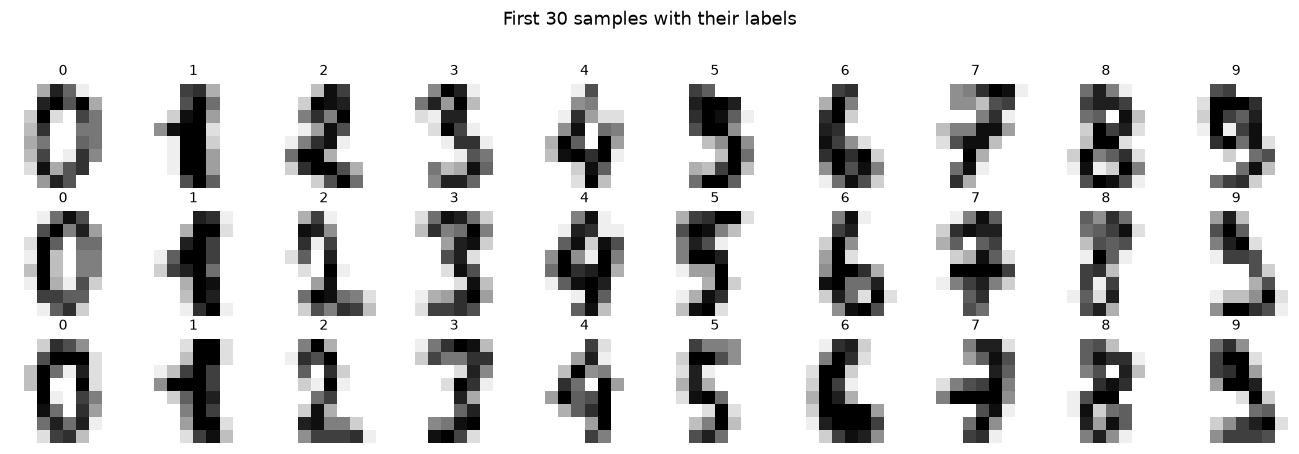

In [118]:
fig, axes = plt.subplots(3, 10, figsize=(12, 4))
for ax, img, label in zip(axes.ravel(), digits.images, y):
    ax.imshow(img, cmap="gray_r")
    ax.set_title(label, fontsize=9)
    ax.axis("off")
fig.suptitle("First 30 samples with their labels", y=1.02)
plt.tight_layout()
plt.show()

### 0.2 Is the dataset balanced?

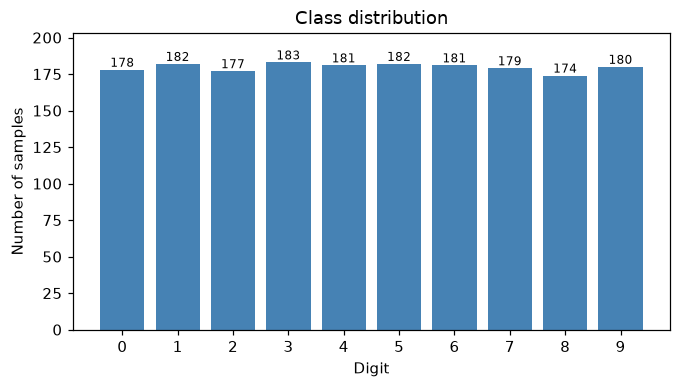

In [119]:
counts = np.bincount(y)
plt.figure(figsize=(7, 3.5))
bars = plt.bar(range(10), counts, color="steelblue")
plt.bar_label(bars, fontsize=8)
plt.xticks(range(10))
plt.xlabel("Digit")
plt.ylabel("Number of samples")
plt.title("Class distribution")
plt.ylim(0, counts.max() + 20)
plt.show()

### 0.3 Average image per digit

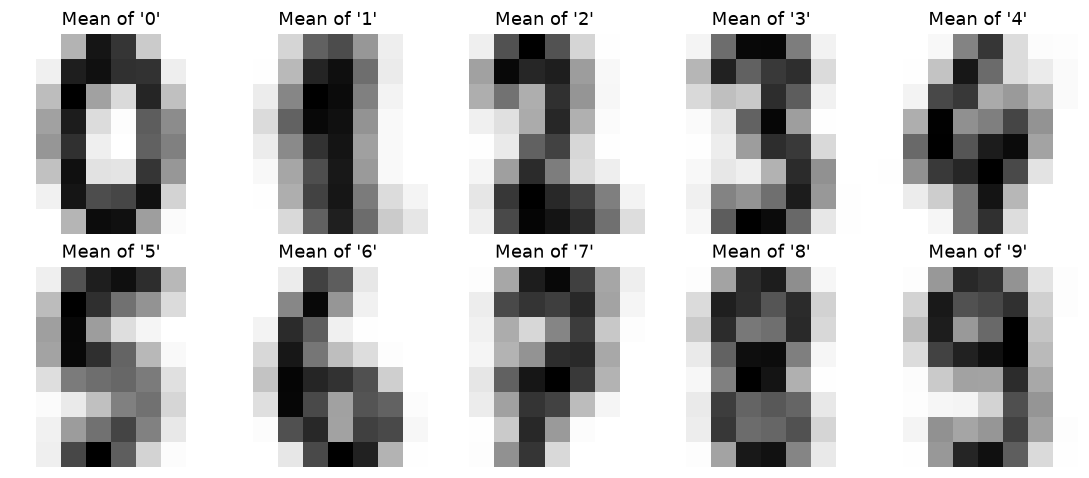

In [120]:
fig, axes = plt.subplots(2, 5, figsize=(10, 4.5))
for d, ax in enumerate(axes.ravel()):
    ax.imshow(X[y == d].mean(axis=0).reshape(8, 8), cmap="gray_r")
    ax.set_title(f"Mean of '{d}'")
    ax.axis("off")
plt.tight_layout()
plt.show()

**What this shows (M0)**
- 1,797 samples, 64 pixel features, 10 classes.
- The classes are almost perfectly balanced (174 to 183 samples each), so plain accuracy is a fair metric here.
- Average images are clearly different for most digits, but similar ones such as 3/5/8 and 4/9 share many pixels. Expect these to be the hardest to separate.

---
## Module 1: Preprocessing
Two decisions matter before training any SVM:

1. **Stratified train/test split:** keeps the same class proportions in both sets, so the test score is reliable.
2. **Feature scaling inside a `Pipeline`:** SVM depends on distances (the RBF kernel uses ||x - x'||), so features on very different scales distort it. Putting the scaler in a Pipeline means it is **fitted on training data only**, which prevents data leakage into the test set.

In [121]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

print("Train:", X_train.shape, " Test:", X_test.shape)
print("Train class counts:", np.bincount(y_train))
print("Test  class counts:", np.bincount(y_test))

Train: (1437, 64)  Test: (360, 64)
Train class counts: [142 146 142 146 145 145 145 143 139 144]
Test  class counts: [36 36 35 37 36 37 36 36 35 36]


### 1.1 Does scaling help? Compare three options with an RBF SVM

,Test accuracy
No scaling,0.9917
StandardScaler,0.9750
MinMaxScaler,0.9917


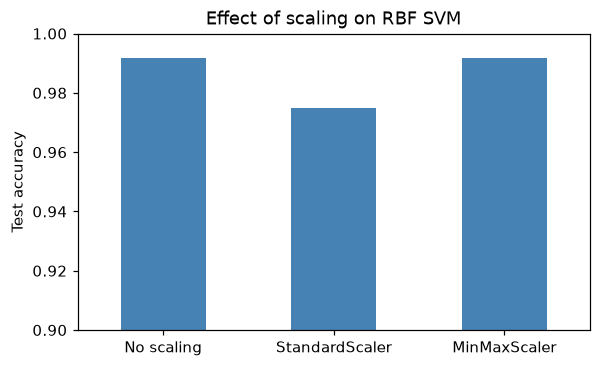

In [122]:
options = {
    "No scaling":      [("svm", SVC(kernel="rbf"))],
    "StandardScaler":  [("scaler", StandardScaler()), ("svm", SVC(kernel="rbf"))],
    "MinMaxScaler":    [("scaler", MinMaxScaler()),   ("svm", SVC(kernel="rbf"))],
}

results = {}
for name, steps in options.items():
    pipe = Pipeline(steps).fit(X_train, y_train)
    results[name] = pipe.score(X_test, y_test)

res_df = pd.DataFrame({"Test accuracy": results}).round(4)
display(res_df)

res_df.plot.bar(legend=False, figsize=(6, 3.5), color="steelblue", rot=0)
plt.ylim(0.9, 1.0)
plt.ylabel("Test accuracy")
plt.title("Effect of scaling on RBF SVM")
plt.show()

### 1.2 Why did StandardScaler not help? Look at the pixels

Pixels with zero variance in training data: 3


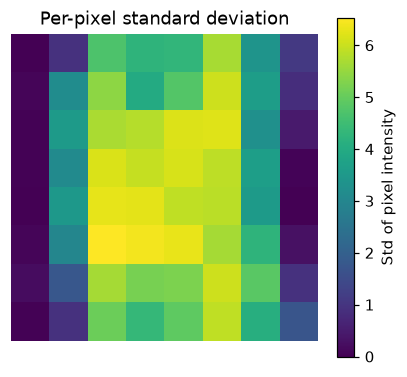

In [123]:
pixel_std = X_train.std(axis=0)
print("Pixels with zero variance in training data:", int((pixel_std == 0).sum()))

plt.figure(figsize=(4.5, 4))
plt.imshow(pixel_std.reshape(8, 8), cmap="viridis")
plt.colorbar(label="Std of pixel intensity")
plt.title("Per-pixel standard deviation")
plt.axis("off")
plt.show()

**What this shows (M1)**
- The split is stratified: train has 1,437 samples and test has 360, with matching class proportions.
- **Honest finding:** scaling did *not* help here. Without scaling and with MinMax we get about 99.2%, while StandardScaler gives about 97.5%.
- Reason: all 64 features are already on the same 0 to 16 scale, so there is nothing to fix. StandardScaler also divides by the standard deviation, which blows up pixels that are almost always 0 (the border pixels, 3 of which have zero variance) and adds noise.
- Takeaway: scaling matters when features have *different* units (as in breast cancer data). For pixels, **MinMax (or dividing by 16)** is the natural choice. We will use `MinMaxScaler` in the Pipeline from here on.
- Keep the scaler in the Pipeline so it is fitted only on training data (no leakage).

---
## Module 2: Margin Intuition (Iris, 2D)
Digits have 64 dimensions, so we cannot draw them. To *see* the margin and support vectors we use **Iris with two features** (petal length and petal width), where everything is 2D.

Key ideas to look for in the plots:
- The **decision boundary** is the line $w \cdot x + b = 0$.
- The two **margin lines** are $w \cdot x + b = \pm 1$, and the gap between them is $2/\|w\|$.
- **Support vectors** (circled) are the only points that define the boundary.

In [124]:
from sklearn.datasets import load_iris

iris = load_iris()
X_iris = iris.data[:, 2:4]            # petal length, petal width
y_iris = iris.target
feat_names = iris.feature_names[2:4]

def plot_svm_2d(model, X, y, ax, title="", colors=("tab:blue", "tab:orange")):
    """Scatter + decision boundary + margin lines + circled support vectors."""
    classes = np.unique(y)
    for c, col in zip(classes, colors):
        ax.scatter(X[y == c, 0], X[y == c, 1], color=col, s=25, edgecolor="k", linewidth=0.3)
    # grid for the decision function
    pad = 0.5
    xx, yy = np.meshgrid(
        np.linspace(X[:, 0].min() - pad, X[:, 0].max() + pad, 300),
        np.linspace(X[:, 1].min() - pad, X[:, 1].max() + pad, 300),
    )
    zz = model.decision_function(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contour(xx, yy, zz, levels=[-1, 0, 1], colors="k",
               linestyles=["--", "-", "--"], linewidths=[1, 2, 1])
    ax.scatter(*model.support_vectors_.T, s=140, facecolors="none",
               edgecolors="red", linewidths=1.6)
    ax.set_xlabel(feat_names[0]); ax.set_ylabel(feat_names[1])
    ax.set_title(title)

### 2.1 Separable case: Setosa vs Versicolor
These two classes can be split perfectly by a line, so a very large $C$ approximates the **hard-margin** SVM.

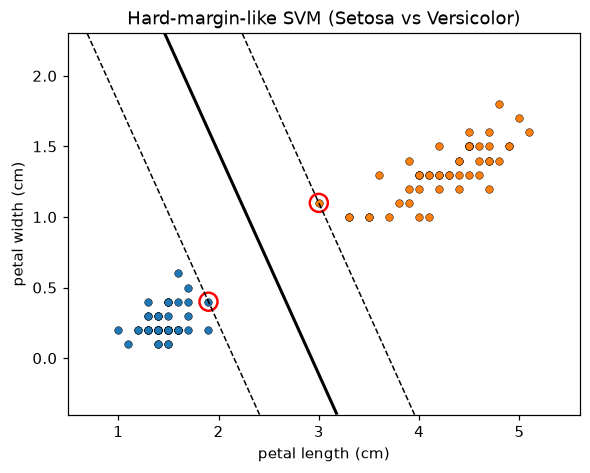

w = [1.294 0.824]   b = [-3.788]
||w|| = 1.534
Margin width 2/||w|| = 1.304
Support vectors per class: [1 1] out of 100 points
Training accuracy: 1.0


In [125]:
mask = y_iris < 2
Xa, ya = X_iris[mask], y_iris[mask]

hard = SVC(kernel="linear", C=1000).fit(Xa, ya)
w = hard.coef_[0]

fig, ax = plt.subplots(figsize=(6, 4.5))
plot_svm_2d(hard, Xa, ya, ax, "Hard-margin-like SVM (Setosa vs Versicolor)")
plt.show()

print("w =", w.round(3), "  b =", hard.intercept_.round(3))
print("||w|| =", round(np.linalg.norm(w), 3))
print("Margin width 2/||w|| =", round(2 / np.linalg.norm(w), 3))
print("Support vectors per class:", hard.n_support_, "out of", len(Xa), "points")
print("Training accuracy:", hard.score(Xa, ya))

**What this shows (2.1)**
- Only **2 of 100 points** are support vectors. Delete any other point and the boundary does not move at all.
- The margin width computed from $2/\|w\|$ (about 1.30) matches the visible gap between the dashed lines.

### 2.2 Overlapping case: Versicolor vs Virginica, and the effect of C
These two classes overlap, so a perfect split is impossible. The **soft-margin** parameter $C$ controls how much we punish points that violate the margin:
- **Small C:** wide margin, many violations allowed (simpler model).
- **Large C:** narrow margin, few violations allowed (risk of overfitting).

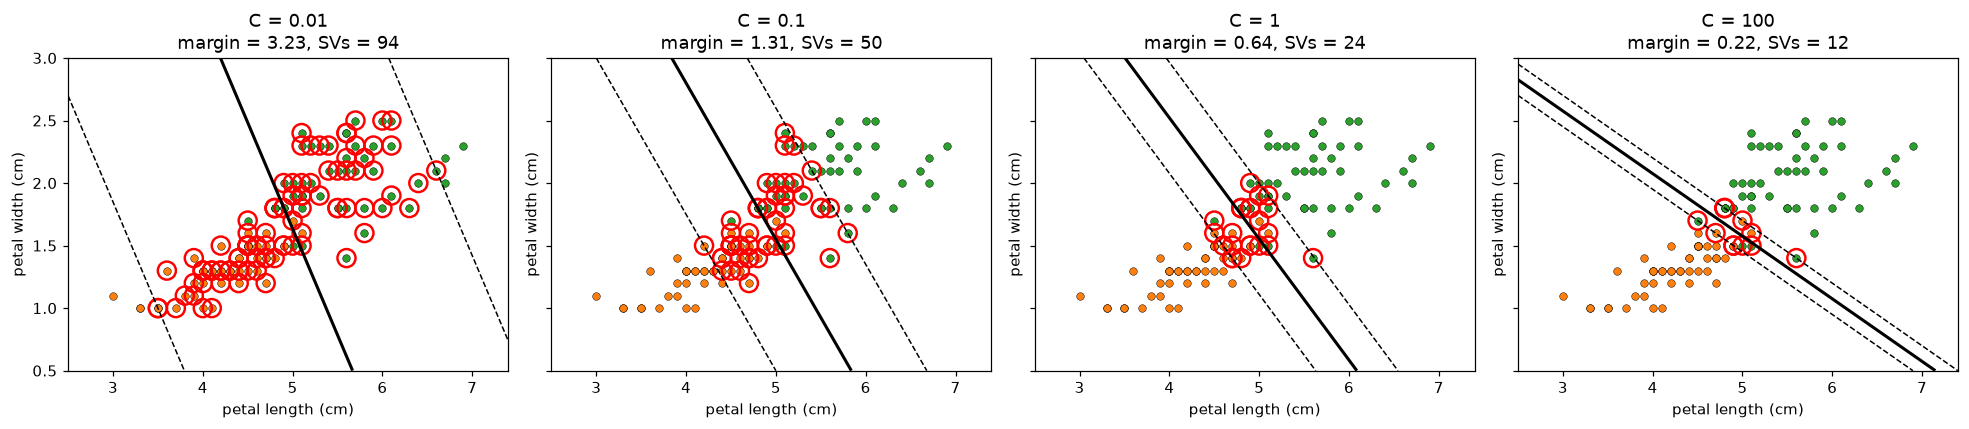

,C,Margin width,Support vectors,Train accuracy
0,0.01,3.230,94,0.92
1,0.10,1.312,50,0.95
2,1.00,0.637,24,0.95
3,100.00,0.224,12,0.94


In [126]:
mask = y_iris > 0
Xb, yb = X_iris[mask], y_iris[mask]

C_values = [0.01, 0.1, 1, 100]
fig, axes = plt.subplots(1, 4, figsize=(18, 4), sharex=True, sharey=True)
rows = []
for ax, C in zip(axes, C_values):
    m = SVC(kernel="linear", C=C).fit(Xb, yb)
    width = 2 / np.linalg.norm(m.coef_[0])
    plot_svm_2d(m, Xb, yb, ax, f"C = {C}\nmargin = {width:.2f}, SVs = {m.n_support_.sum()}",
                colors=("tab:orange", "tab:green"))
    rows.append({"C": C, "Margin width": round(width, 3),
                 "Support vectors": int(m.n_support_.sum()),
                 "Train accuracy": round(m.score(Xb, yb), 3)})
plt.tight_layout()
plt.show()

display(pd.DataFrame(rows))

**What this shows (2.2)**
- As $C$ grows from 0.01 to 100, the margin shrinks from about 3.2 to about 0.2, and the number of support vectors drops from 94 to 12.
- Small $C$ makes a wide, forgiving margin where almost every point is a support vector. Large $C$ forces a tight fit around the data.
- Training accuracy barely changes (92% to 95%), so the extra complexity from a large $C$ buys almost nothing. This is the bias-variance trade-off, and we will tune $C$ properly with cross-validation in Module 8.

---
## Module 3: Math Notes
We go from intuition to formulas in 7 steps, then verify everything on a tiny 4-point example computed by hand and checked against sklearn.

### 3.1 Hyperplane and decision rule
A linear classifier uses the function $f(x) = w \cdot x + b$. The set $f(x) = 0$ is a **hyperplane** (a line in 2D, a plane in 3D). Prediction: $\hat{y} = \text{sign}(f(x))$.

### 3.2 Margin
The distance from a point $x_i$ to the hyperplane is $\dfrac{|w \cdot x_i + b|}{\|w\|}$.
We scale $w, b$ so that the closest points satisfy $y_i (w \cdot x_i + b) = 1$. Then the distance from the boundary to the nearest point on each side is $1/\|w\|$, so the **total margin is $2/\|w\|$**.

### 3.3 Hard-margin optimization
Maximizing the margin $2/\|w\|$ is the same as minimizing $\|w\|$, which we write as minimizing $\tfrac12\|w\|^2$ (convex and smooth):

$$\min_{w,b}\ \tfrac12\|w\|^2 \quad \text{subject to} \quad y_i(w \cdot x_i + b) \ge 1 \ \ \forall i$$

**Why a large margin?** It leaves the most room for new points to land on the right side, which tends to generalize better.

### 3.4 Soft margin and C
Real data overlaps, so we allow **slack** $\xi_i \ge 0$ for points that violate the margin:

$$\min_{w,b,\xi}\ \tfrac12\|w\|^2 + C\sum_i \xi_i \quad \text{subject to} \quad y_i(w \cdot x_i + b) \ge 1 - \xi_i$$

$C$ is the price of a violation: large $C$ means a narrow margin and few violations, small $C$ means a wide margin and more violations. This is exactly what we saw in 2.2.

### 3.5 Hinge-loss view
Eliminating the slack gives an unconstrained problem:

$$\min_{w,b}\ \tfrac12\|w\|^2 + C\sum_i \max\big(0,\ 1 - y_i(w \cdot x_i + b)\big)$$

The **hinge loss** is 0 for points safely outside the margin, and grows linearly for points inside it or misclassified. This form is what we minimize with gradient descent in Module 4.

### 3.6 Dual form and support vectors
Using Lagrange multipliers $\alpha_i \ge 0$ the problem becomes:

$$\max_{\alpha}\ \sum_i \alpha_i - \tfrac12\sum_{i,j}\alpha_i\alpha_j y_i y_j\,(x_i \cdot x_j) \quad \text{s.t.} \quad \sum_i \alpha_i y_i = 0,\ \ 0 \le \alpha_i \le C$$

and the solution is $w = \sum_i \alpha_i y_i x_i$. By the KKT conditions, $\alpha_i > 0$ **only for points on or inside the margin**. Those are the **support vectors**. All other points have $\alpha_i = 0$ and do not affect the model.
Two benefits: the data appear only through dot products $x_i \cdot x_j$ (which enables kernels), and prediction only needs the support vectors.

### 3.7 Kernel trick
Replace every dot product $x_i \cdot x_j$ by a kernel $K(x_i, x_j) = \phi(x_i)\cdot\phi(x_j)$. We get the effect of mapping data into a higher-dimensional space $\phi$ **without ever computing $\phi$**.

| Kernel | Formula | Behaviour |
|---|---|---|
| Linear | $x \cdot x'$ | straight boundary |
| Polynomial | $(\gamma\, x \cdot x' + r)^d$ | curved boundary of degree $d$ |
| RBF | $\exp(-\gamma\|x - x'\|^2)$ | very flexible, similarity falls with distance |

For RBF, $\gamma$ sets how far one point's influence reaches: **large $\gamma$** gives a tight, wiggly boundary (overfitting), **small $\gamma$** gives a smooth one. (RBF corresponds to an infinite-dimensional $\phi$, which is why the trick is needed.)

### 3.8 Multiclass
SVM is binary, so for $k$ classes we combine binary models:
- **One-vs-Rest (OvR):** $k$ classifiers (class $c$ vs everything else), pick the largest score. For digits, 10 models.
- **One-vs-One (OvO):** $k(k-1)/2$ classifiers, one per pair, and the class with the most votes wins. For digits, 45 models. sklearn's `SVC` uses OvO.

### 3.9 Worked example: 4 points by hand
Positive class ($y=+1$): $(3,3)$ and $(4,4)$. Negative class ($y=-1$): $(1,1)$ and $(0,0)$.

**Step 1: find the support vectors.** By symmetry the closest opposite pair is $(1,1)$ and $(3,3)$. The points $(4,4)$ and $(0,0)$ are further away.

**Step 2: solve for $w, b$.** Because the data lie along the diagonal, $w = (a, a)$. The two support vectors must satisfy $f = +1$ and $f = -1$:
- $(3,3)$: $6a + b = 1$
- $(1,1)$: $2a + b = -1$

Subtract: $4a = 2$, so $a = 0.5$ and $b = -2$. Hence $w = (0.5, 0.5)$, $b = -2$.

**Step 3: margin.** $\|w\| = \sqrt{0.25 + 0.25} = 0.7071$, so margin $= 2/0.7071 = 2.828$. This equals the distance between $(1,1)$ and $(3,3)$, which is $\sqrt{8} = 2.828$. ✓

**Step 4: dual check.** $w = \sum \alpha_i y_i x_i$ and $\sum \alpha_i y_i = 0$ force equal alphas on the two support vectors: $\alpha(3,3) - \alpha(1,1) = (2\alpha, 2\alpha) = (0.5, 0.5)$, so $\alpha = 0.25$. The other two points have $\alpha = 0$.

Now we verify this with code.

In [127]:
X_toy = np.array([[3, 3], [4, 4], [1, 1], [0, 0]], dtype=float)
y_toy = np.array([1, 1, -1, -1])

toy = SVC(kernel="linear", C=1e6).fit(X_toy, y_toy)   # huge C ~ hard margin

w_hand, b_hand = np.array([0.5, 0.5]), -2.0
print("Hand-computed   w =", w_hand, " b =", b_hand)
print("sklearn         w =", toy.coef_[0], " b =", toy.intercept_[0])
print()
print("Support vectors found by sklearn:\n", toy.support_vectors_)
print("Dual coefficients (alpha_i * y_i):", toy.dual_coef_[0])
print()
print("Margin 2/||w|| =", round(2 / np.linalg.norm(toy.coef_[0]), 3))
print("y_i * f(x_i) for all points:", y_toy * (X_toy @ w_hand + b_hand))
print("  -> equals 1 for support vectors, greater than 1 for the others")

Hand-computed   w = [0.5 0.5]  b = -2.0
sklearn         w = [0.5 0.5]  b = -1.9999999999999996

Support vectors found by sklearn:
 [[1. 1.]
 [3. 3.]]
Dual coefficients (alpha_i * y_i): [-0.25  0.25]

Margin 2/||w|| = 2.828
y_i * f(x_i) for all points: [1. 2. 1. 2.]
  -> equals 1 for support vectors, greater than 1 for the others


### 3.10 RBF kernel by hand
For $\gamma = 0.5$, compare the similarity of a close pair and a far pair of points.

In [128]:
def rbf(a, b, gamma=0.5):
    return np.exp(-gamma * np.sum((a - b) ** 2))

p, q_near, q_far = np.array([1.0, 1.0]), np.array([1.5, 1.0]), np.array([4.0, 4.0])
print("K(p, near) =", round(rbf(p, q_near), 4), " (distance^2 = 0.25)")
print("K(p, far)  =", round(rbf(p, q_far), 6),  " (distance^2 = 18)")

# Effect of gamma on the same far pair
for g in [0.01, 0.1, 0.5, 2]:
    print(f"gamma = {g:<4}: K(p, far) = {rbf(p, q_far, g):.4f}")

K(p, near) = 0.8825  (distance^2 = 0.25)
K(p, far)  = 0.000123  (distance^2 = 18)
gamma = 0.01: K(p, far) = 0.8353
gamma = 0.1 : K(p, far) = 0.1653
gamma = 0.5 : K(p, far) = 0.0001
gamma = 2   : K(p, far) = 0.0000


**What this shows (M3)**
- The hand calculation, the sklearn result, and the dual coefficients all agree: $w=(0.5, 0.5)$, $b=-2$, margin $=2.828$, and only 2 support vectors with $\alpha = 0.25$ each.
- The two non-support points have $y_i f(x_i) > 1$, so they are safely outside the margin and have $\alpha = 0$.
- The RBF kernel turns distance into similarity between 0 and 1: near points are close to 1, far points close to 0. A larger $\gamma$ makes similarity drop off faster, so each point influences only its close neighbours.

---
## Module 4: Linear SVM From Scratch (binary: digit 3 vs 8)
We now build the SVM ourselves using only NumPy, by minimizing the **hinge-loss objective** from Module 3.5 with **sub-gradient descent**.

**Objective** (written as an average so it is independent of dataset size, with $\lambda = \dfrac{1}{Cn}$ so it matches sklearn's $C$):

$$J(w,b) = \frac{\lambda}{2}\|w\|^2 + \frac1n\sum_i \max\big(0,\ 1 - y_i(w\cdot x_i + b)\big)$$

**Sub-gradient** (the hinge has a kink, so we use a valid sub-gradient). Only points that **violate the margin** ($y_i f(x_i) < 1$) contribute:

$$\nabla_w J = \lambda w - \frac1n\sum_{i\in V} y_i x_i, \qquad \nabla_b J = -\frac1n\sum_{i\in V} y_i$$

**Update:** $w \leftarrow w - \eta_t \nabla_w J$ with a decaying step $\eta_t = \eta_0/\sqrt t$. This links directly to the dual: points with zero hinge loss (outside the margin) have no pull on $w$, just as non-support vectors have $\alpha=0$.

Digits 3 and 8 are chosen because they look alike (two loops), so they make a meaningful test.

In [129]:
# Scale pixels to [0, 1]; scaler is fitted on training data only
scaler = MinMaxScaler().fit(X_train)
Xtr_s, Xte_s = scaler.transform(X_train), scaler.transform(X_test)

class LinearSVMScratch:
    """Linear SVM trained by sub-gradient descent on the regularized hinge loss.
    Labels must be -1 / +1."""
    def __init__(self, C=1.0, lr=0.1, n_epochs=300):
        self.C, self.lr, self.n_epochs = C, lr, n_epochs

    def fit(self, X, y):
        n, d = X.shape
        lam = 1.0 / (self.C * n)
        self.w, self.b = np.zeros(d), 0.0
        self.loss_history, self.acc_history = [], []
        for t in range(1, self.n_epochs + 1):
            viol = y * (X @ self.w + self.b) < 1              # margin violators
            grad_w = lam * self.w - (y[viol, None] * X[viol]).sum(axis=0) / n
            grad_b = -y[viol].sum() / n
            step = self.lr / np.sqrt(t)
            self.w -= step * grad_w
            self.b -= step * grad_b
            self.loss_history.append(self.objective(X, y))
            self.acc_history.append(np.mean(self.predict(X) == y))
        return self

    def objective(self, X, y):
        lam = 1.0 / (self.C * len(y))
        hinge = np.maximum(0, 1 - y * (X @ self.w + self.b)).mean()
        return 0.5 * lam * self.w @ self.w + hinge

    def decision_function(self, X):
        return X @ self.w + self.b

    def predict(self, X):
        return np.where(self.decision_function(X) >= 0, 1, -1)

### 4.1 Train on digits 3 vs 8
We label **8 as +1** and **3 as -1**.

In [130]:
tr = np.isin(y_train, [3, 8]); te = np.isin(y_test, [3, 8])
X38_tr, y38_tr = Xtr_s[tr], np.where(y_train[tr] == 8, 1, -1)
X38_te, y38_te = Xte_s[te], np.where(y_test[te] == 8, 1, -1)
print("Train samples:", len(y38_tr), " Test samples:", len(y38_te))

scratch = LinearSVMScratch(C=10, lr=100, n_epochs=5000).fit(X38_tr, y38_tr)

print("Initial objective :", round(scratch.loss_history[0], 4))
print("Final objective   :", round(scratch.loss_history[-1], 4))
print("Train accuracy    :", round(np.mean(scratch.predict(X38_tr) == y38_tr), 4))
print("Test accuracy     :", round(np.mean(scratch.predict(X38_te) == y38_te), 4))

Train samples: 285  Test samples: 72
Initial objective : 1.5839
Final objective   : 0.0053
Train accuracy    : 1.0
Test accuracy     : 1.0


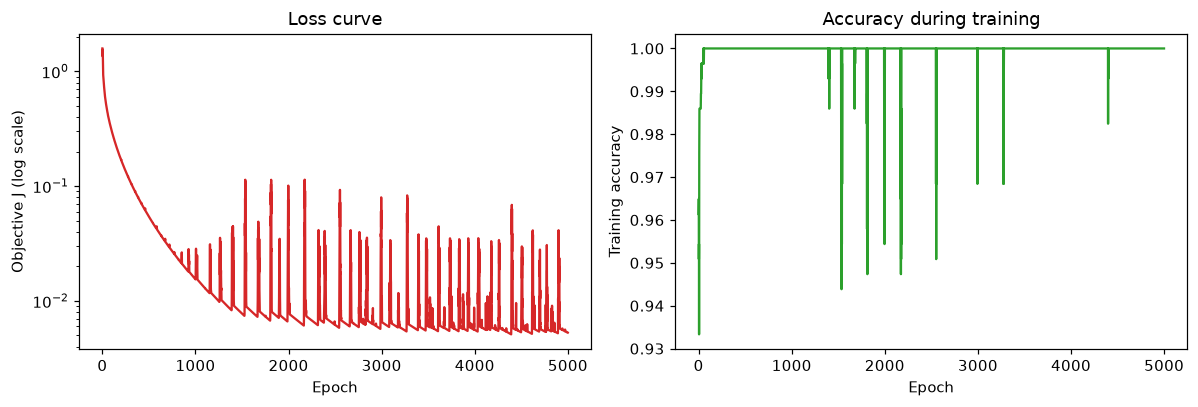

In [131]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(scratch.loss_history, color="tab:red")
axes[0].set_yscale("log")
axes[0].set(xlabel="Epoch", ylabel="Objective J (log scale)", title="Loss curve")
axes[1].plot(scratch.acc_history, color="tab:green")
axes[1].set(xlabel="Epoch", ylabel="Training accuracy", title="Accuracy during training")
plt.tight_layout()
plt.show()

### 4.2 Compare with sklearn's `SVC(kernel='linear')`

In [132]:
sk = SVC(kernel="linear", C=10).fit(X38_tr, y38_tr)

def objective(w, b, X, y, C):
    lam = 1.0 / (C * len(y))
    return 0.5 * lam * w @ w + np.maximum(0, 1 - y * (X @ w + b)).mean()

cos = scratch.w @ sk.coef_[0] / (np.linalg.norm(scratch.w) * np.linalg.norm(sk.coef_[0]))
compare = pd.DataFrame({
    "Scratch": [np.mean(scratch.predict(X38_tr) == y38_tr), np.mean(scratch.predict(X38_te) == y38_te),
                objective(scratch.w, scratch.b, X38_tr, y38_tr, 10), 2 / np.linalg.norm(scratch.w)],
    "sklearn": [sk.score(X38_tr, y38_tr), sk.score(X38_te, y38_te),
                objective(sk.coef_[0], sk.intercept_[0], X38_tr, y38_tr, 10), 2 / np.linalg.norm(sk.coef_[0])],
}, index=["Train accuracy", "Test accuracy", "Objective J", "Margin 2/||w||"]).round(4)
display(compare)

print("Cosine similarity of the two weight vectors:", round(cos, 3))
print("Test predictions that agree:", np.mean(scratch.predict(X38_te) == sk.predict(X38_te)))
print("sklearn support vectors per class:", sk.n_support_)

,Scratch,sklearn
Train accuracy,1.0000,1.0000
Test accuracy,1.0000,1.0000
Objective J,0.0053,0.0039
Margin 2/||w||,0.3640,0.4240


Cosine similarity of the two weight vectors: 0.978
Test predictions that agree: 1.0
sklearn support vectors per class: [14 16]


### 4.3 What did the model learn?
For a linear model on images, the weight vector $w$ can be drawn as an 8x8 picture. **Red pixels vote for 8, blue pixels vote for 3.**

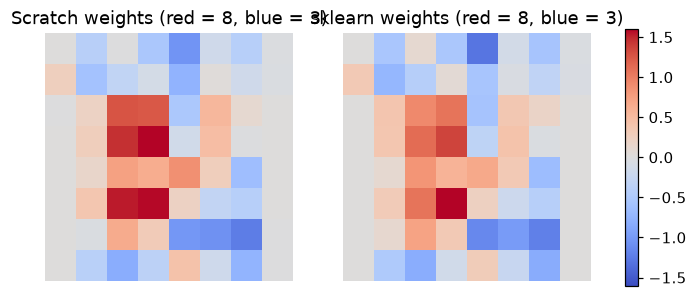

In [133]:
fig, axes = plt.subplots(1, 2, figsize=(8, 3.8))
for ax, wvec, name in zip(axes, [scratch.w, sk.coef_[0]], ["Scratch", "sklearn"]):
    lim = np.abs(wvec).max()
    im = ax.imshow(wvec.reshape(8, 8), cmap="coolwarm", vmin=-lim, vmax=lim)
    ax.set_title(f"{name} weights (red = 8, blue = 3)")
    ax.axis("off")
plt.colorbar(im, ax=axes, shrink=0.8)
plt.show()

**What this shows (M4)**
- Our 20-line NumPy SVM separates 3 from 8 perfectly: 100% on both the 285 training and 72 test images, the same as sklearn.
- The loss curve falls from about 1.58 to 0.005 and training accuracy reaches 100%. Sub-gradient descent converges slowly (the error shrinks roughly like $1/\sqrt t$), so 5,000 epochs were needed.
- It is close to sklearn but not identical. Our objective is 0.0053 against sklearn's exact optimum of 0.0039, the weight vectors point almost the same way (cosine similarity 0.978), and the test predictions agree on every image. Sklearn solves the dual problem exactly, while we stop early.
- sklearn needs only 30 support vectors (14 + 16) out of 285 training images, so about 10% of the data defines the boundary.

---
## Module 5: One-vs-Rest Multiclass From Scratch (all 10 digits)
Our binary SVM becomes a 10-class classifier with **One-vs-Rest (OvR)**:

1. For each digit $c$, train a binary SVM: digit $c$ ($+1$) against all other digits ($-1$). That gives **10 models**.
2. For a new image, compute all 10 scores $f_c(x) = w_c\cdot x + b_c$.
3. Predict the digit with the **largest score**: $\hat y = \arg\max_c f_c(x)$.

In [134]:
class OneVsRestScratch:
    """Multiclass wrapper: one LinearSVMScratch per class, predict by argmax score."""
    def __init__(self, **svm_kwargs):
        self.svm_kwargs = svm_kwargs

    def fit(self, X, y):
        self.classes_ = np.unique(y)
        self.models_ = [LinearSVMScratch(**self.svm_kwargs).fit(X, np.where(y == c, 1, -1))
                        for c in self.classes_]
        return self

    def decision_function(self, X):
        return np.column_stack([m.decision_function(X) for m in self.models_])

    def predict(self, X):
        return self.classes_[np.argmax(self.decision_function(X), axis=1)]

ovr = OneVsRestScratch(C=10, lr=100, n_epochs=3000).fit(Xtr_s, y_train)
pred_ovr = ovr.predict(Xte_s)
print("Models trained:", len(ovr.models_))
print("Scratch OvR  train accuracy:", round(np.mean(ovr.predict(Xtr_s) == y_train), 4))
print("Scratch OvR  test accuracy :", round(np.mean(pred_ovr == y_test), 4))

Models trained: 10
Scratch OvR  train accuracy: 0.9805
Scratch OvR  test accuracy : 0.9583


### 5.1 One prediction step by step
The 10 scores for a single test image: the tallest bar wins.

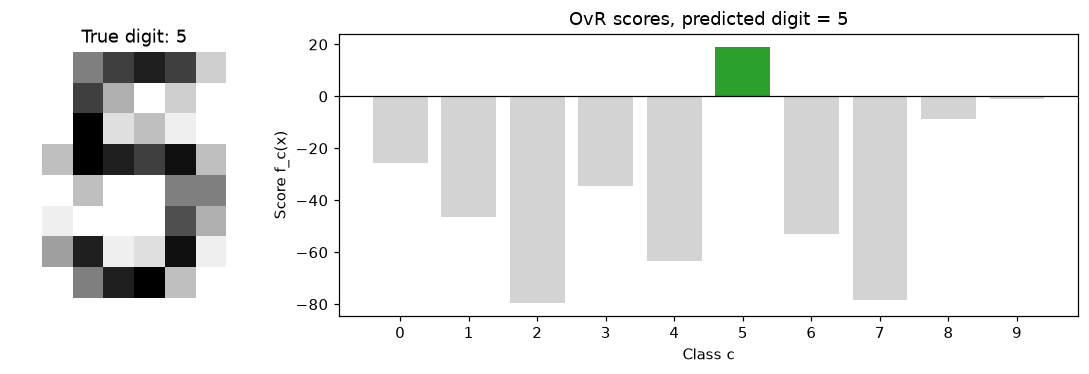

In [135]:
i = 0
scores = ovr.decision_function(Xte_s[i:i + 1])[0]

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), gridspec_kw={"width_ratios": [1, 3]})
axes[0].imshow(X_test[i].reshape(8, 8), cmap="gray_r")
axes[0].set_title(f"True digit: {y_test[i]}")
axes[0].axis("off")
colors = ["tab:green" if c == scores.argmax() else "lightgray" for c in range(10)]
axes[1].bar(range(10), scores, color=colors)
axes[1].axhline(0, color="k", lw=0.8)
axes[1].set_xticks(range(10))
axes[1].set(xlabel="Class c", ylabel="Score f_c(x)", title=f"OvR scores, predicted digit = {scores.argmax()}")
plt.tight_layout()
plt.show()

### 5.2 Compare with sklearn

,Train accuracy,Test accuracy
Scratch OvR (linear),0.9805,0.9583
sklearn OvR (linear SVC),0.9916,0.9528
sklearn SVC OvO (linear),1.0000,0.9750
sklearn SVC OvO (RBF),0.9979,0.9917


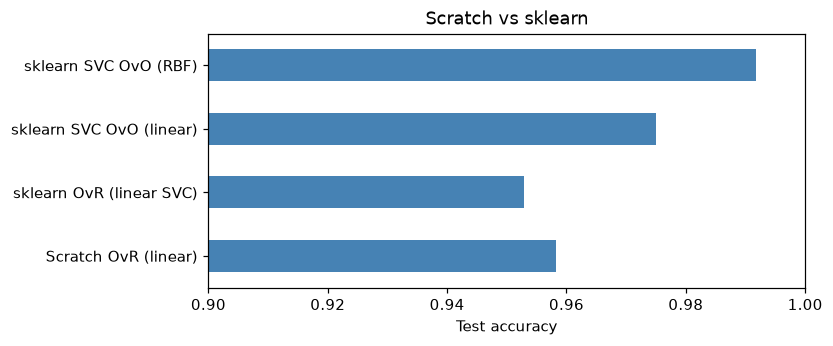

In [136]:
from sklearn.multiclass import OneVsRestClassifier

models = {
    "Scratch OvR (linear)":        ovr,
    "sklearn OvR (linear SVC)":    OneVsRestClassifier(SVC(kernel="linear", C=10)).fit(Xtr_s, y_train),
    "sklearn SVC OvO (linear)":    SVC(kernel="linear", C=10).fit(Xtr_s, y_train),
    "sklearn SVC OvO (RBF)":       SVC(kernel="rbf").fit(Xtr_s, y_train),
}
table = pd.DataFrame({
    name: {"Train accuracy": np.mean(m.predict(Xtr_s) == y_train),
           "Test accuracy":  np.mean(m.predict(Xte_s) == y_test)}
    for name, m in models.items()
}).T.round(4)
display(table)

table["Test accuracy"].plot.barh(figsize=(7, 3), color="steelblue")
plt.xlim(0.9, 1.0)
plt.xlabel("Test accuracy")
plt.title("Scratch vs sklearn")
plt.show()

### 5.3 What did each of the 10 models learn?

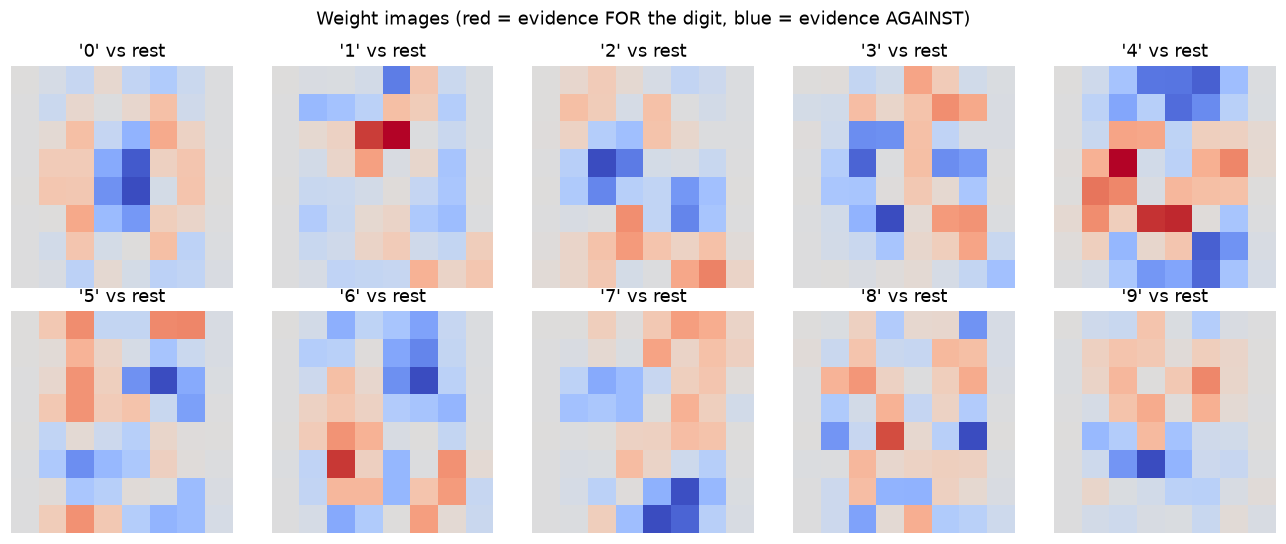

In [137]:
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for c, (ax, m) in enumerate(zip(axes.ravel(), ovr.models_)):
    lim = np.abs(m.w).max()
    ax.imshow(m.w.reshape(8, 8), cmap="coolwarm", vmin=-lim, vmax=lim)
    ax.set_title(f"'{c}' vs rest")
    ax.axis("off")
fig.suptitle("Weight images (red = evidence FOR the digit, blue = evidence AGAINST)")
plt.tight_layout()
plt.show()

### 5.4 Where does it go wrong?

Most common mistakes (true -> predicted : count)
  1 -> 8 : 3
  1 -> 3 : 2
  1 -> 6 : 2
  8 -> 1 : 2
  1 -> 4 : 1


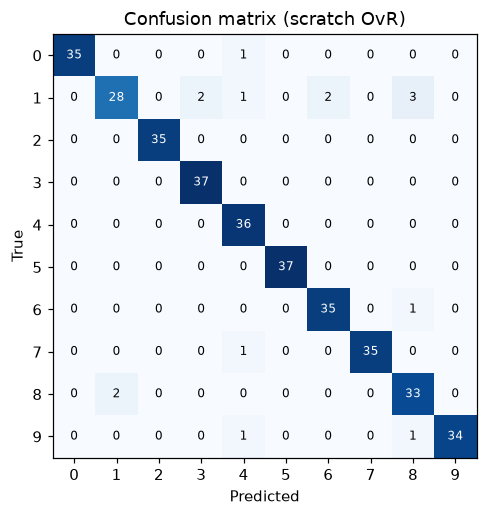

In [138]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, pred_ovr)
off = cm.copy(); np.fill_diagonal(off, 0)
top = np.dstack(np.unravel_index(np.argsort(-off.ravel())[:5], off.shape))[0]
print("Most common mistakes (true -> predicted : count)")
for t, p in top:
    print(f"  {t} -> {p} : {off[t, p]}")

fig, ax = plt.subplots(figsize=(5.5, 5))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(10)); ax.set_yticks(range(10))
ax.set(xlabel="Predicted", ylabel="True", title="Confusion matrix (scratch OvR)")
for r in range(10):
    for c in range(10):
        ax.text(c, r, cm[r, c], ha="center", va="center",
                color="white" if cm[r, c] > cm.max() / 2 else "black", fontsize=8)
plt.show()

**What this shows (M5)**
- A binary SVM plus an `argmax` over 10 scores gives a working 10-class classifier: **95.8% test accuracy** from scratch, in about 2 seconds.
- It matches sklearn's own OvR linear SVM (95.3%). The 0.5-point gap is about 2 images out of 360, so treat them as equal.
- sklearn's default OvO linear SVM gets 97.5%, and the **RBF kernel reaches 99.2%**. Even on digits, the curved boundary beats any set of straight lines. This motivates the kernel work in Modules 6 to 8.
- The scratch model makes only about 15 errors in 360, spread thinly (the top pair, 1 predicted as 8, happens 3 times). Our earlier guess of 3/5/8 and 4/9 confusions does not stand out for this linear model. With such small counts we will redo the error analysis with the best tuned model in Module 9.
- The weight images show that each classifier learns a recognizable template of its digit.

---
## Module 6: The Kernel Trick (moons and circles)
Linear SVM can only draw straight lines. Many real problems are not separable that way. Here we use two toy 2D datasets, so we can *see* the effect:
- **make_moons:** two interleaving half-circles.
- **make_circles:** one class inside a ring of the other. **No straight line can ever separate these.**

In [139]:
from sklearn.datasets import make_moons, make_circles
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401  (enables 3D axes)

datasets = {
    "Moons":   make_moons(n_samples=300, noise=0.15, random_state=42),
    "Circles": make_circles(n_samples=300, noise=0.08, factor=0.4, random_state=42),
}

def plot_boundary(model, X, y, ax, title=""):
    """Filled decision regions + data points + circled support vectors."""
    pad = 0.4
    xx, yy = np.meshgrid(np.linspace(X[:, 0].min() - pad, X[:, 0].max() + pad, 300),
                         np.linspace(X[:, 1].min() - pad, X[:, 1].max() + pad, 300))
    zz = model.decision_function(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, zz, levels=[-100, 0, 100], colors=["#fdd9b5", "#b9d7ea"], alpha=0.7)
    ax.contour(xx, yy, zz, levels=[0], colors="k", linewidths=2)
    ax.scatter(X[y == 0, 0], X[y == 0, 1], c="tab:orange", edgecolor="k", s=20)
    ax.scatter(X[y == 1, 0], X[y == 1, 1], c="tab:blue", edgecolor="k", s=20)
    ax.scatter(*model.support_vectors_.T, s=90, facecolors="none", edgecolors="red", linewidths=1)
    ax.set_title(title)
    ax.set_xticks([]); ax.set_yticks([])

### 6.1 Linear vs RBF kernel on both datasets

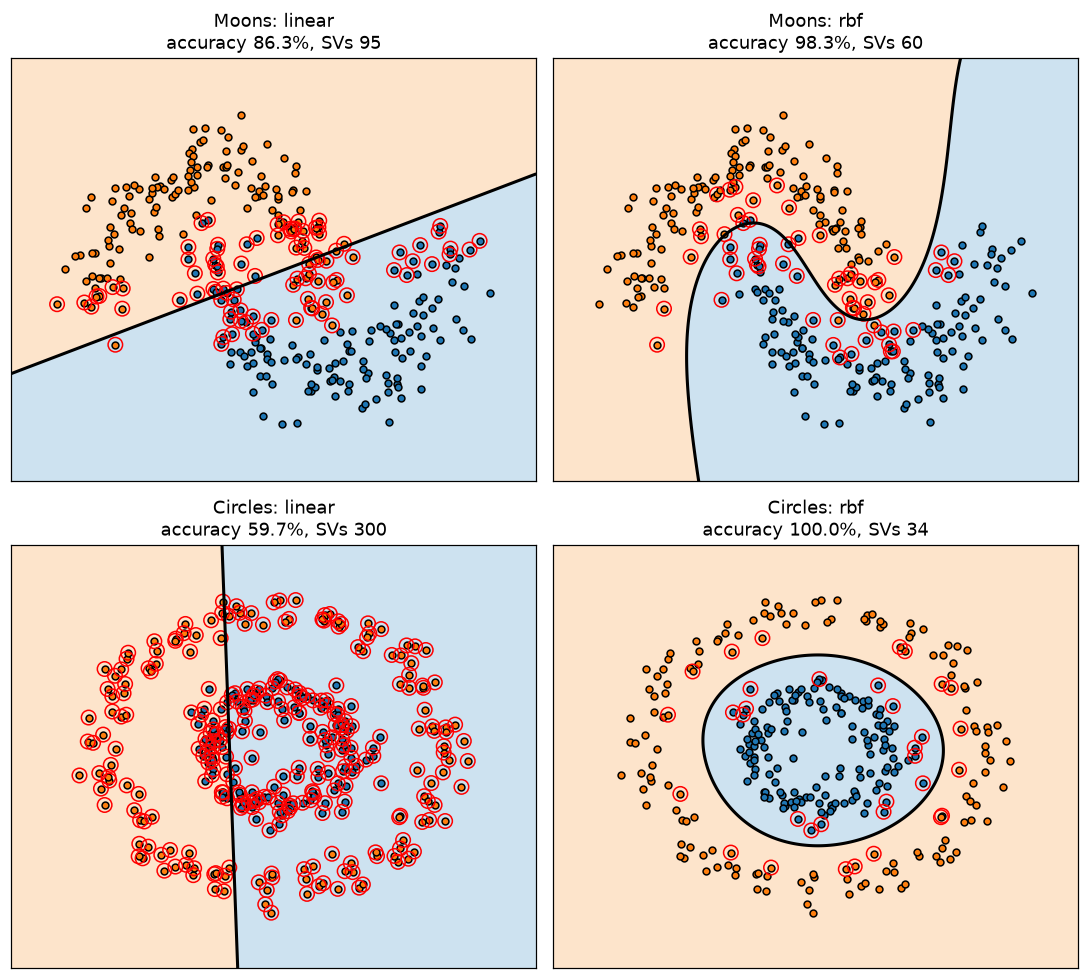

,Dataset,Kernel,Accuracy,Support vectors
0,Moons,linear,0.863,95
1,Moons,rbf,0.983,60
2,Circles,linear,0.597,300
3,Circles,rbf,1.000,34


In [140]:
fig, axes = plt.subplots(2, 2, figsize=(10, 9))
rows = []
for r, (name, (Xd, yd)) in enumerate(datasets.items()):
    for c, kernel in enumerate(["linear", "rbf"]):
        m = SVC(kernel=kernel, C=1, gamma="scale").fit(Xd, yd)
        acc = m.score(Xd, yd)
        plot_boundary(m, Xd, yd, axes[r, c],
                      f"{name}: {kernel}\naccuracy {acc:.1%}, SVs {m.n_support_.sum()}")
        rows.append({"Dataset": name, "Kernel": kernel, "Accuracy": round(acc, 3),
                     "Support vectors": int(m.n_support_.sum())})
plt.tight_layout()
plt.show()
display(pd.DataFrame(rows))

**What this shows (6.1)**
- On circles, the linear SVM scores about 60% (barely better than guessing) and every point becomes a support vector. The RBF kernel scores 100% with only 34 support vectors.
- On moons, linear reaches about 86% and RBF about 98%.

### 6.2 Why it works: lifting circles into 3D
The kernel trick is equivalent to adding new features. For circles, add a third coordinate $z = x^2 + y^2$ (the squared distance from the centre):

$$\phi(x, y) = (x,\ y,\ x^2 + y^2)$$

The inner ring has a small $z$ and the outer ring has a large $z$, so in 3D **a flat plane separates them**.

Linear SVM in the lifted 3D space -> accuracy: 1.0
Plane: w = [-0.115  0.291 -5.927]  b = 3.226


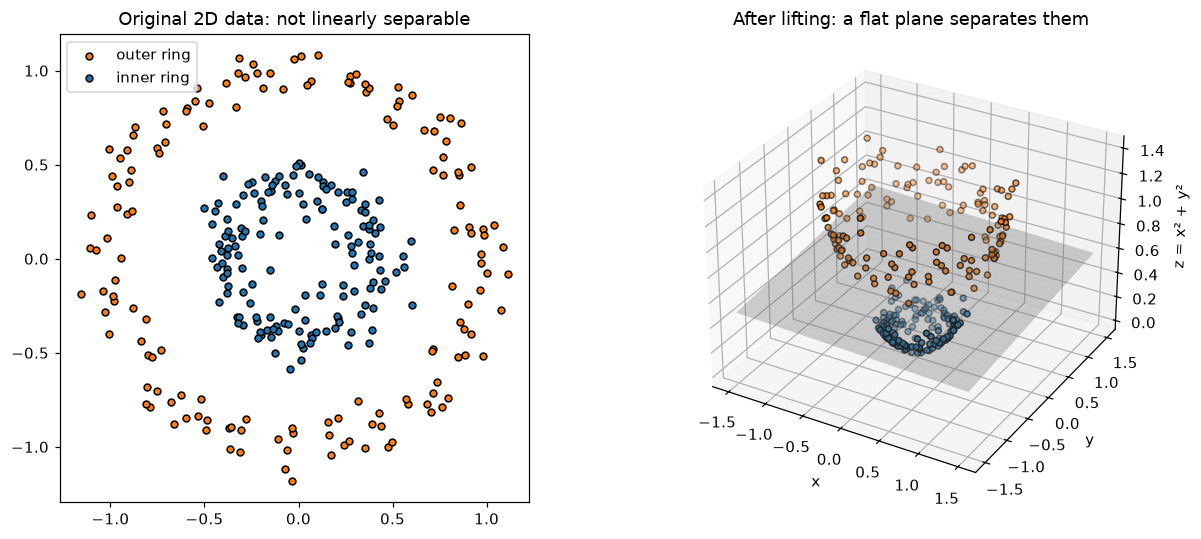

In [141]:
Xc, yc = datasets["Circles"]
Z = np.c_[Xc, (Xc ** 2).sum(axis=1)]            # explicit lift to 3D

lifted = SVC(kernel="linear", C=10).fit(Z, yc)  # a LINEAR SVM, but in 3D
w, b = lifted.coef_[0], lifted.intercept_[0]
print("Linear SVM in the lifted 3D space -> accuracy:", lifted.score(Z, yc))
print("Plane: w =", w.round(3), " b =", round(b, 3))

# the separating plane z = -(w0*x + w1*y + b) / w2
gx, gy = np.meshgrid(np.linspace(-1.5, 1.5, 30), np.linspace(-1.5, 1.5, 30))
gz = -(w[0] * gx + w[1] * gy + b) / w[2]

fig = plt.figure(figsize=(12, 5))
ax1 = fig.add_subplot(1, 2, 1)
ax1.scatter(Xc[yc == 0, 0], Xc[yc == 0, 1], c="tab:orange", edgecolor="k", s=20, label="outer ring")
ax1.scatter(Xc[yc == 1, 0], Xc[yc == 1, 1], c="tab:blue", edgecolor="k", s=20, label="inner ring")
ax1.set_title("Original 2D data: not linearly separable")
ax1.set_aspect("equal"); ax1.legend()

ax2 = fig.add_subplot(1, 2, 2, projection="3d")
ax2.scatter(*Z[yc == 0].T, c="tab:orange", edgecolor="k", s=15)
ax2.scatter(*Z[yc == 1].T, c="tab:blue", edgecolor="k", s=15)
ax2.plot_surface(gx, gy, gz, alpha=0.3, color="gray")
ax2.set_xlabel("x"); ax2.set_ylabel("y"); ax2.set_zlabel("z = x² + y²")
ax2.set_title("After lifting: a flat plane separates them")
plt.tight_layout()
plt.show()

### 6.3 Interactive 3D view (Plotly)
Rotate and zoom this one during the presentation. If Plotly is not installed, run `pip install plotly`.

In [142]:
try:
    import plotly.graph_objects as go
    fig = go.Figure()
    fig.add_trace(go.Scatter3d(x=Z[yc == 0, 0], y=Z[yc == 0, 1], z=Z[yc == 0, 2], mode="markers",
                               marker=dict(size=3, color="orange"), name="outer ring"))
    fig.add_trace(go.Scatter3d(x=Z[yc == 1, 0], y=Z[yc == 1, 1], z=Z[yc == 1, 2], mode="markers",
                               marker=dict(size=3, color="royalblue"), name="inner ring"))
    fig.add_trace(go.Surface(x=gx, y=gy, z=gz, opacity=0.35, showscale=False,
                             colorscale=[[0, "gray"], [1, "gray"]], name="separating plane"))
    fig.update_layout(title="Circles lifted to 3D with z = x² + y²", height=520,
                      scene=dict(xaxis_title="x", yaxis_title="y", zaxis_title="z = x² + y²",
                                 zaxis=dict(range=[0, 2.5])))
    fig.show()
except ImportError:
    print("Plotly is not installed. Run: pip install plotly")

Plotly is not installed. Run: pip install plotly


### 6.4 Bring the plane back to 2D
Every point where the plane cuts the paraboloid satisfies $z = $ constant, which means $x^2 + y^2 = r^2$: a **circle** in the original space.

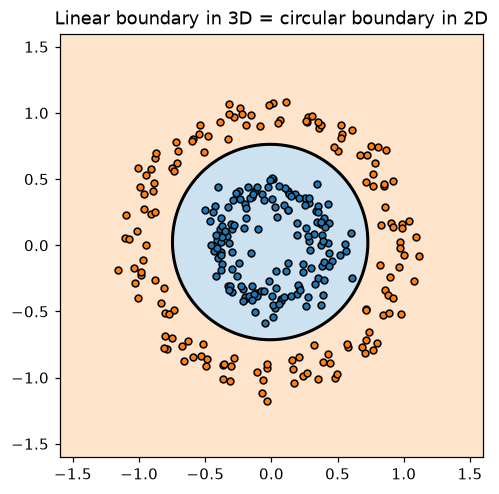

Mean radius inner ring: 0.41, outer ring: 1.00
Plane height near the origin axis is about z = 0.54, i.e. a circle of radius about 0.74


In [143]:
fig, ax = plt.subplots(figsize=(5.5, 5))
pad = 0.4
xx, yy = np.meshgrid(np.linspace(-1.6, 1.6, 300), np.linspace(-1.6, 1.6, 300))
Zgrid = np.c_[xx.ravel(), yy.ravel(), (xx.ravel() ** 2 + yy.ravel() ** 2)]
zz = lifted.decision_function(Zgrid).reshape(xx.shape)
ax.contourf(xx, yy, zz, levels=[-100, 0, 100], colors=["#fdd9b5", "#b9d7ea"], alpha=0.7)
ax.contour(xx, yy, zz, levels=[0], colors="k", linewidths=2)
ax.scatter(Xc[yc == 0, 0], Xc[yc == 0, 1], c="tab:orange", edgecolor="k", s=20)
ax.scatter(Xc[yc == 1, 0], Xc[yc == 1, 1], c="tab:blue", edgecolor="k", s=20)
ax.set_aspect("equal"); ax.set_title("Linear boundary in 3D = circular boundary in 2D")
plt.show()

r_inner = np.sqrt((Xc[yc == 1] ** 2).sum(axis=1)).mean()
r_outer = np.sqrt((Xc[yc == 0] ** 2).sum(axis=1)).mean()
z_plane = -(b) / w[2]
print(f"Mean radius inner ring: {r_inner:.2f}, outer ring: {r_outer:.2f}")
print(f"Plane height near the origin axis is about z = {z_plane:.2f}, i.e. a circle of radius about {np.sqrt(z_plane):.2f}")

### 6.5 The trick: never compute the lift
Computing $\phi$ explicitly gets expensive in many dimensions (RBF corresponds to *infinitely many* features). The kernel gives the same dot product directly. For the degree-2 polynomial kernel, with $\phi(x) = (x_1^2,\ \sqrt2\,x_1x_2,\ x_2^2)$, we have $K(a,b) = (a\cdot b)^2 = \phi(a)\cdot\phi(b)$.

In [144]:
a, b_ = np.array([1.0, 2.0]), np.array([3.0, -1.0])
phi = lambda v: np.array([v[0] ** 2, np.sqrt(2) * v[0] * v[1], v[1] ** 2])

print("Kernel   K(a,b) = (a.b)^2      =", (a @ b_) ** 2)
print("Explicit phi(a) . phi(b)        =", round(phi(a) @ phi(b_), 6))

Kernel   K(a,b) = (a.b)^2      = 1.0
Explicit phi(a) . phi(b)        = 1.0


### 6.6 Effect of gamma in the RBF kernel (moons with more noise)
We now hold out 30% of the data to see overfitting.

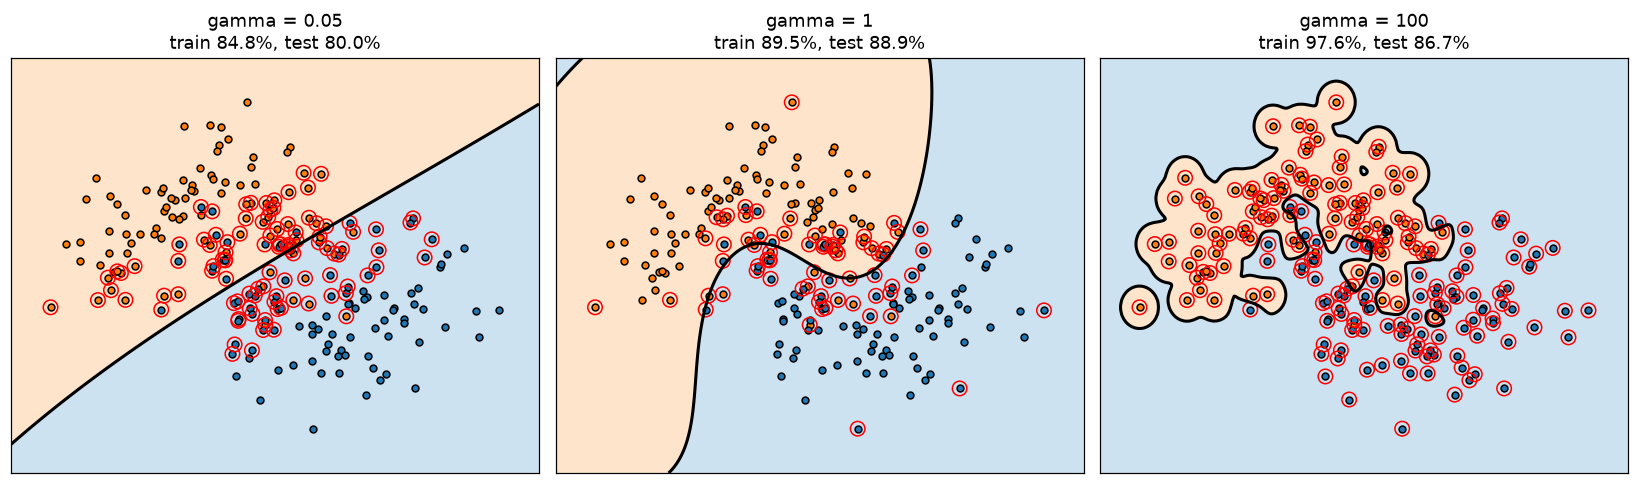

,gamma,Train acc,Test acc,Support vectors
0,0.05,0.848,0.800,103
1,1.00,0.895,0.889,70
2,100.00,0.976,0.867,196


In [145]:
Xn, yn = make_moons(n_samples=300, noise=0.3, random_state=42)
Xn_tr, Xn_te, yn_tr, yn_te = train_test_split(Xn, yn, test_size=0.3, stratify=yn, random_state=42)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
rows = []
for ax, g in zip(axes, [0.05, 1, 100]):
    m = SVC(kernel="rbf", gamma=g, C=1).fit(Xn_tr, yn_tr)
    tr_acc, te_acc = m.score(Xn_tr, yn_tr), m.score(Xn_te, yn_te)
    plot_boundary(m, Xn_tr, yn_tr, ax, f"gamma = {g}\ntrain {tr_acc:.1%}, test {te_acc:.1%}")
    rows.append({"gamma": g, "Train acc": round(tr_acc, 3), "Test acc": round(te_acc, 3),
                 "Support vectors": int(m.n_support_.sum())})
plt.tight_layout()
plt.show()
display(pd.DataFrame(rows))

**What this shows (M6)**
- Circles cannot be split by any line, yet a *linear* SVM in the lifted space $(x, y, x^2+y^2)$ separates them perfectly (100%) with a nearly flat plane. That plane maps back to a circle of radius about 0.7, between the inner ring (about 0.4) and the outer ring (about 1.0).
- The kernel trick gives this lift for free: $(a\cdot b)^2$ equals the dot product in the 3D feature space (both print 1.0), without building the features.
- **$\gamma$ controls flexibility.** Tiny $\gamma = 0.05$ underfits (train 85%, test 80%). $\gamma = 100$ overfits (train 98%, test 87%, a big gap, and a wiggly boundary around single points). A medium $\gamma = 1$ is best (test 89%). The test set here has only 90 points, so treat small differences with caution. We tune $\gamma$ properly in Module 8.

---
## Module 7: sklearn Kernels on Digits
Back to the real problem. We now train sklearn's `SVC` with different kernels on the full 10-class digits data (using the scaled data from Module 4) and compare accuracy, model size, and speed. Default hyperparameters for now; Module 8 tunes them.

In [146]:
import time

kernels = {
    "Linear":          dict(kernel="linear"),
    "Poly (degree 2)": dict(kernel="poly", degree=2),
    "Poly (degree 3)": dict(kernel="poly", degree=3),
    "Poly (degree 4)": dict(kernel="poly", degree=4),
    "RBF":             dict(kernel="rbf"),
}

rows, fitted = [], {}
for name, params in kernels.items():
    t0 = time.perf_counter()
    m = SVC(C=1, **params).fit(Xtr_s, y_train)
    fit_time = time.perf_counter() - t0
    test_acc = m.score(Xte_s, y_test)
    fitted[name] = m
    rows.append({"Kernel": name,
                 "Train acc": round(m.score(Xtr_s, y_train), 4),
                 "Test acc": round(test_acc, 4),
                 "Test errors (of 360)": int(round((1 - test_acc) * len(y_test))),
                 "Support vectors": int(m.n_support_.sum()),
                 "% of train as SV": round(100 * m.n_support_.sum() / len(y_train), 1),
                 "Fit time (s)": round(fit_time, 3)})
kernel_table = pd.DataFrame(rows).set_index("Kernel")
display(kernel_table)
print("RBF gamma used by gamma='scale':", round(fitted["RBF"]._gamma, 4))

,Train acc,Test acc,Test errors (of 360),Support vectors,% of train as SV,Fit time (s)
Kernel,,,,,,
Linear,0.9986,0.9861,5,425,29.6,0.058
Poly (degree 2),0.9986,0.9889,4,519,36.1,0.055
Poly (degree 3),0.9993,0.9861,5,465,32.4,0.054
Poly (degree 4),1.0000,0.9861,5,427,29.7,0.059
RBF,0.9979,0.9917,3,662,46.1,0.078


RBF gamma used by gamma='scale': 0.11


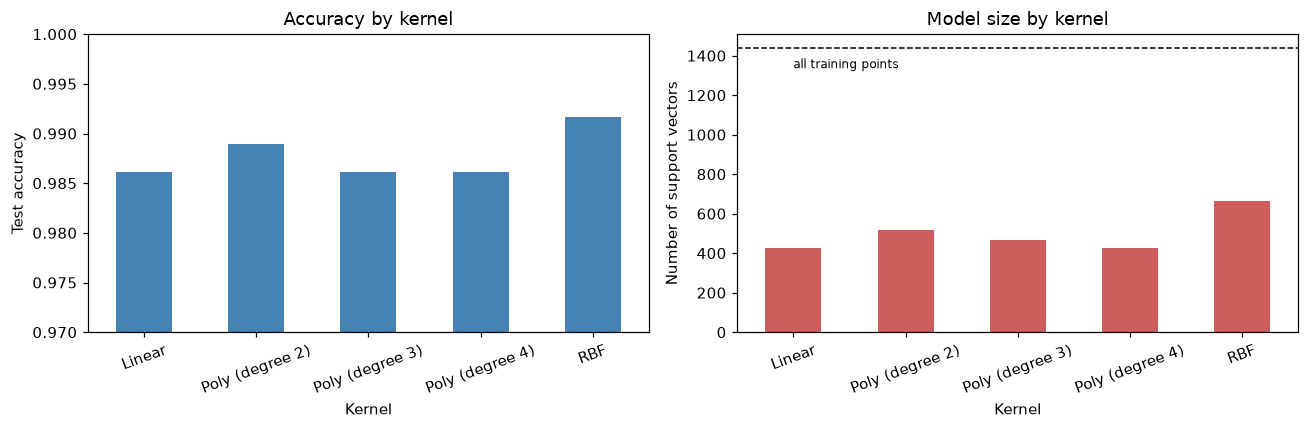

In [147]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
kernel_table["Test acc"].plot.bar(ax=axes[0], color="steelblue", rot=20)
axes[0].set_ylim(0.97, 1.0); axes[0].set_ylabel("Test accuracy"); axes[0].set_title("Accuracy by kernel")
kernel_table["Support vectors"].plot.bar(ax=axes[1], color="indianred", rot=20)
axes[1].axhline(len(y_train), color="k", ls="--", lw=1)
axes[1].text(0, len(y_train) * 0.93, "all training points", fontsize=8)
axes[1].set_ylabel("Number of support vectors"); axes[1].set_title("Model size by kernel")
plt.tight_layout()
plt.show()

**What this shows (M7)**
- Every kernel does very well: **98.6% to 99.2% test accuracy**. RBF is best with 3 errors out of 360, linear has 5. That difference is 2 images, too small to call a winner, so we use cross-validation in Module 8.
- The same linear kernel scored 97.5% in Module 5 with $C=10$ and 98.6% here with $C=1$. So $C$ matters, and a larger $C$ was worse (more overfitting). This is a good example of why we tune.
- Our scratch OvR from Module 5 (95.8%) is about 3 points behind sklearn's linear SVM. The scratch version stops early and uses OvR, whereas sklearn solves the problem exactly and uses OvO.
- **Support vectors are not "just a few" here.** Linear needs about 30% of the training images and RBF about 46%. With 64 dimensions and 10 overlapping classes, many images sit near some class boundary. This is a useful contrast with the 2 support vectors in the Iris example.
- Training takes well under a second for every kernel, so live demos and grid search are safe.

---
## Module 8: Hyperparameter Tuning (C and gamma)
So far we used default settings. The two knobs of an RBF SVM are:
- $C$: price of margin violations (large = tight fit, small = smooth).
- $\gamma$: reach of each point's influence (large = wiggly, small = smooth).

**Method: `GridSearchCV` with 5-fold stratified cross-validation, on the training set only.** Each combination is trained on 4 folds and scored on the 5th, five times, and the scores are averaged. The test set is untouched until the very end, so it stays an honest final check.

We put `MinMaxScaler` and `SVC` together in one `Pipeline` and give it the **raw** pixels. Then in every fold the scaler is fitted only on that fold's training part (no leakage).

In [148]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
pipe = Pipeline([("scaler", MinMaxScaler()), ("svm", SVC(kernel="rbf"))])
param_grid = {"svm__C":     [0.1, 1, 10, 100],
              "svm__gamma": [0.001, 0.01, 0.1, 1]}

grid_search = GridSearchCV(pipe, param_grid, cv=cv, return_train_score=True)
grid_search.fit(X_train, y_train)          # raw pixels: the scaler lives inside the pipeline

print("Combinations x folds:", len(grid_search.cv_results_["params"]), "x", cv.get_n_splits())
print("Best parameters     :", grid_search.best_params_)
print("Best CV accuracy    :", round(grid_search.best_score_, 4))
print("Test accuracy (used once):", round(grid_search.score(X_test, y_test), 4))

Combinations x folds: 16 x 5
Best parameters     : {'svm__C': 1, 'svm__gamma': 0.1}
Best CV accuracy    : 0.9882
Test accuracy (used once): 0.9917


### 8.1 Heatmaps: validation accuracy and the overfitting gap

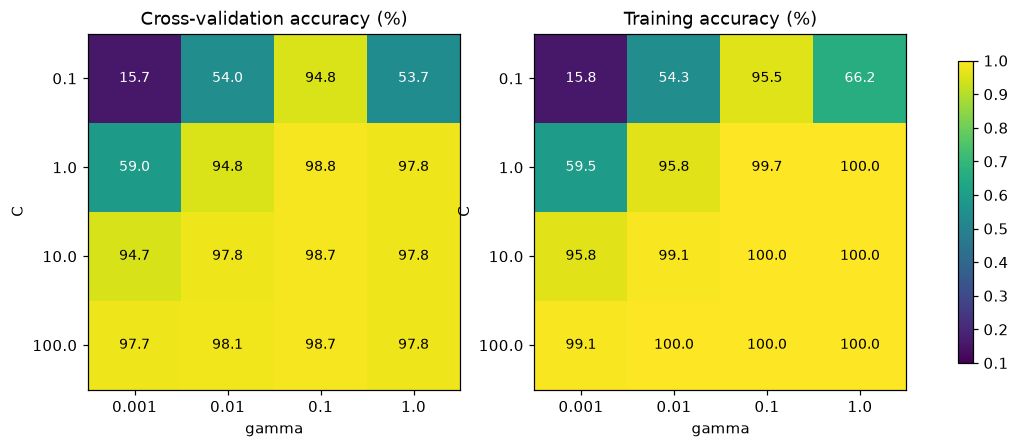

Overfitting gap (train minus CV accuracy):


param_svm__gamma,0.001,0.010,0.100,1.000
param_svm__C,,,,
0.1,0.001,0.003,0.007,0.125
1.0,0.005,0.010,0.009,0.022
10.0,0.011,0.013,0.013,0.022
100.0,0.014,0.019,0.013,0.022


In [149]:
res = pd.DataFrame(grid_search.cv_results_)
cv_mat    = res.pivot(index="param_svm__C", columns="param_svm__gamma", values="mean_test_score")
train_mat = res.pivot(index="param_svm__C", columns="param_svm__gamma", values="mean_train_score")

def heatmap(mat, ax, title, vmin=None):
    im = ax.imshow(mat.values, cmap="viridis", vmin=vmin, vmax=1.0, aspect="auto")
    ax.set_xticks(range(mat.shape[1])); ax.set_xticklabels(mat.columns)
    ax.set_yticks(range(mat.shape[0])); ax.set_yticklabels(mat.index)
    ax.set(xlabel="gamma", ylabel="C", title=title)
    for i in range(mat.shape[0]):
        for j in range(mat.shape[1]):
            v = mat.values[i, j]
            ax.text(j, i, f"{100 * v:.1f}", ha="center", va="center",
                    color="white" if v < 0.9 else "black", fontsize=9)
    return im

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
im = heatmap(cv_mat, axes[0], "Cross-validation accuracy (%)", vmin=0.1)
heatmap(train_mat, axes[1], "Training accuracy (%)", vmin=0.1)
fig.colorbar(im, ax=axes, shrink=0.85)
plt.show()

gap = (train_mat - cv_mat).round(3)
print("Overfitting gap (train minus CV accuracy):")
display(gap)

### 8.2 The best few settings
The standard deviation across folds tells us which differences are real.

In [150]:
top = (res.sort_values("rank_test_score")
          [["param_svm__C", "param_svm__gamma", "mean_test_score", "std_test_score", "rank_test_score"]]
          .head(6).rename(columns={"param_svm__C": "C", "param_svm__gamma": "gamma",
                                   "mean_test_score": "CV acc", "std_test_score": "CV std",
                                   "rank_test_score": "rank"}))
display(top.round(4).reset_index(drop=True))

,C,gamma,CV acc,CV std,rank
0,1.0,0.10,0.9882,0.0036,1
1,10.0,0.10,0.9875,0.0042,2
2,100.0,0.10,0.9875,0.0042,2
3,100.0,0.01,0.9805,0.0064,4
4,10.0,0.01,0.9784,0.0067,5
5,100.0,1.00,0.9784,0.0056,6


### 8.3 Settle the kernel question with cross-validation
In Module 7 the kernels differed by only 1 to 2 test images, which is too small to judge. Cross-validation uses all 1,437 training images 5 times, which is a much steadier comparison.

,Mean CV acc,Std
Linear,0.9784,0.0051
Poly (degree 2),0.9875,0.0061
Poly (degree 3),0.9916,0.0028
RBF,0.9882,0.0036


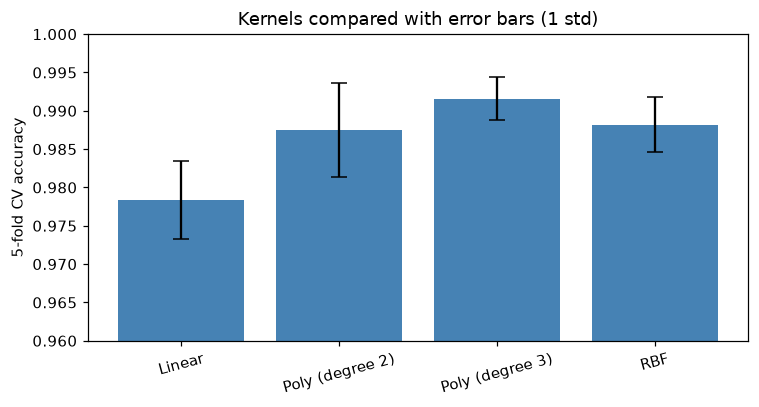

In [151]:
kernel_cv = {}
for name, params in {"Linear": dict(kernel="linear"),
                     "Poly (degree 2)": dict(kernel="poly", degree=2),
                     "Poly (degree 3)": dict(kernel="poly", degree=3),
                     "RBF": dict(kernel="rbf")}.items():
    p_ = Pipeline([("scaler", MinMaxScaler()), ("svm", SVC(C=1, **params))])
    kernel_cv[name] = cross_val_score(p_, X_train, y_train, cv=cv)

kcv = pd.DataFrame({"Mean CV acc": {k: v.mean() for k, v in kernel_cv.items()},
                    "Std": {k: v.std() for k, v in kernel_cv.items()}}).round(4)
display(kcv)

plt.figure(figsize=(7, 3.8))
plt.bar(kcv.index, kcv["Mean CV acc"], yerr=kcv["Std"], capsize=5, color="steelblue")
plt.ylim(0.96, 1.0); plt.ylabel("5-fold CV accuracy"); plt.xticks(rotation=15)
plt.title("Kernels compared with error bars (1 std)")
plt.tight_layout()
plt.show()

**What this shows (M8)**
- The search took 16 settings x 5 folds = 80 fits. Best: **$C=1$, $\gamma=0.1$**, with CV accuracy 98.8% and test accuracy 99.2% (3 errors in 360).
- The heatmap has a clear **ridge at $\gamma = 0.1$**. Once $\gamma$ is right, any $C \ge 1$ gives about 98.8%, so $C$ matters much less than $\gamma$.
- The bad regions match the theory. Tiny $\gamma$ with small $C$ is **underfitting** (15.7% CV accuracy at $C=0.1$, $\gamma=0.001$). Large $\gamma$ shows **overfitting**: at $\gamma=1$ the training accuracy is 100% but CV is only about 97.8%. At $C=0.1$, $\gamma=1$ it collapses to 53.7%.
- Honest note: tuning did not beat the default. sklearn's default $\gamma$ (`'scale'`, about 0.11) is almost exactly the best value, and default RBF scored the same 98.8% in CV. The value of the search is that it *confirms* the default and shows how sensitive the model is.
- Kernels by CV: linear 97.8%, poly-2 98.8%, RBF 98.8%, poly-3 99.2%. **Linear is clearly worst** (about 1 point lower). The other three are within about one standard deviation of each other, so there is no real winner among them. We keep the tuned RBF as our final model because it is the standard choice and its tuning is documented.

---
## Module 9: Evaluation and Baselines
We now evaluate the tuned model (`grid_search.best_estimator_`) on the held-out test set. The classes are balanced, so accuracy is a fair headline number. We also report per-class precision, recall and F1, because they show **which digits** the model struggles with.
- **Precision of digit $d$:** of the images predicted as $d$, how many truly are $d$.
- **Recall of digit $d$:** of the true $d$ images, how many were found.
- **F1:** the harmonic mean of the two. **Macro** averages treat all 10 digits equally.

In [152]:
from sklearn.metrics import classification_report, confusion_matrix, f1_score, accuracy_score

best_model = grid_search.best_estimator_
pred = best_model.predict(X_test)

print(f"Test accuracy : {accuracy_score(y_test, pred):.4f}   ({(pred != y_test).sum()} errors out of {len(y_test)})")
print(f"Macro F1      : {f1_score(y_test, pred, average='macro'):.4f}")

report = pd.DataFrame(classification_report(y_test, pred, output_dict=True)).T.round(3)
display(report.iloc[:10])

Test accuracy : 0.9917   (3 errors out of 360)
Macro F1      : 0.9916


,precision,recall,f1-score,support
0,1.000,1.000,1.000,36.0
1,0.947,1.000,0.973,36.0
2,1.000,1.000,1.000,35.0
3,1.000,1.000,1.000,37.0
4,1.000,1.000,1.000,36.0
5,1.000,1.000,1.000,37.0
6,1.000,1.000,1.000,36.0
7,0.973,1.000,0.986,36.0
8,1.000,0.943,0.971,35.0
9,1.000,0.972,0.986,36.0


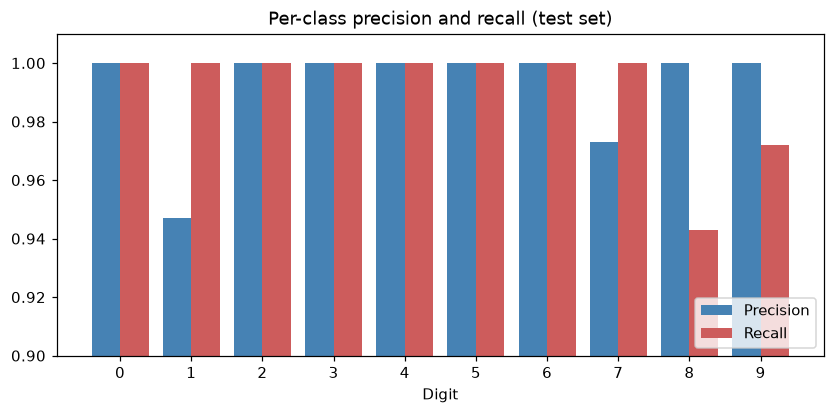

In [153]:
per_class = report.iloc[:10]
x = np.arange(10)
plt.figure(figsize=(9, 3.8))
plt.bar(x - 0.2, per_class["precision"], 0.4, label="Precision", color="steelblue")
plt.bar(x + 0.2, per_class["recall"],    0.4, label="Recall",    color="indianred")
plt.xticks(x); plt.ylim(0.9, 1.01); plt.xlabel("Digit"); plt.legend(loc="lower right")
plt.title("Per-class precision and recall (test set)")
plt.show()

### 9.1 Confusion matrices
The test set has only 3 errors, which is too few to find patterns. So we also build a second matrix from **5-fold cross-validated predictions on all 1,797 images**, where every image is predicted by a model that did not see it. (The hyperparameters came from training data only, so this is for error analysis, not for reporting accuracy.)

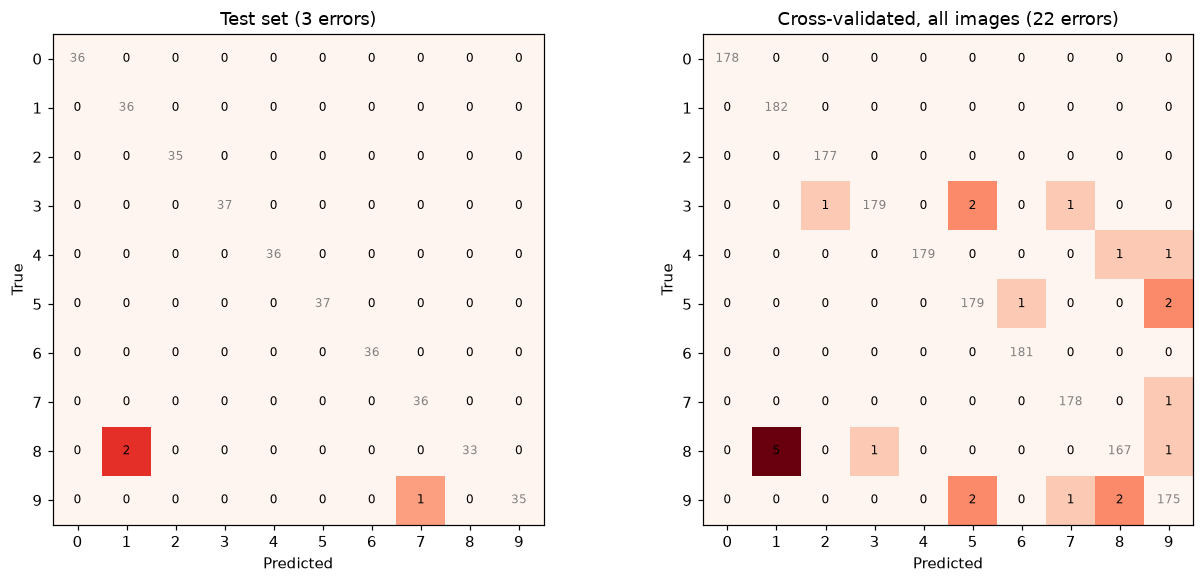

Most confused digit pairs (errors in either direction), cross-validated:
1 and 8    5
5 and 9    4
8 and 9    3
3 and 5    2
7 and 9    2

Per-digit recall (cross-validated):
0    1.000
1    1.000
2    1.000
3    0.978
4    0.989
5    0.984
6    1.000
7    0.994
8    0.960
9    0.972


In [154]:
from sklearn.model_selection import cross_val_predict

pred_cv = cross_val_predict(best_model, X, y, cv=cv)

def show_cm(cm, ax, title):
    ax.imshow(np.where(np.eye(10, dtype=bool), 0, cm), cmap="Reds", vmax=max(3, (cm - np.diag(np.diag(cm))).max()))
    ax.set_xticks(range(10)); ax.set_yticks(range(10))
    ax.set(xlabel="Predicted", ylabel="True", title=title)
    for r in range(10):
        for c in range(10):
            ax.text(c, r, cm[r, c], ha="center", va="center", fontsize=8,
                    color="gray" if r == c else "black")

fig, axes = plt.subplots(1, 2, figsize=(12, 5.4))
show_cm(confusion_matrix(y_test, pred), axes[0], f"Test set ({(pred != y_test).sum()} errors)")
show_cm(confusion_matrix(y, pred_cv),   axes[1], f"Cross-validated, all images ({(pred_cv != y).sum()} errors)")
plt.tight_layout()
plt.show()

cm_cv = confusion_matrix(y, pred_cv)
off = cm_cv - np.diag(np.diag(cm_cv))
pair = pd.Series({f"{i} and {j}": off[i, j] + off[j, i] for i in range(10) for j in range(i + 1, 10)})
print("Most confused digit pairs (errors in either direction), cross-validated:")
print(pair.sort_values(ascending=False).head(5).to_string())
print("\nPer-digit recall (cross-validated):")
print(pd.Series(cm_cv.diagonal() / cm_cv.sum(axis=1)).round(3).to_string())

### 9.2 Baselines: is the SVM actually better?
We compare against Logistic Regression and k-NN, each with the same `MinMaxScaler` pipeline, the same 5-fold CV on the training set, and the same test set.

,CV acc,CV std,Test acc,Test macro F1
Model,,,,
"SVM (RBF, tuned)",0.9882,0.0036,0.9917,0.9916
Logistic Regression,0.9638,0.0090,0.9583,0.9576
k-NN (k=3),0.9875,0.0052,0.9861,0.9859
k-NN (k=5),0.9868,0.0074,0.9833,0.9830


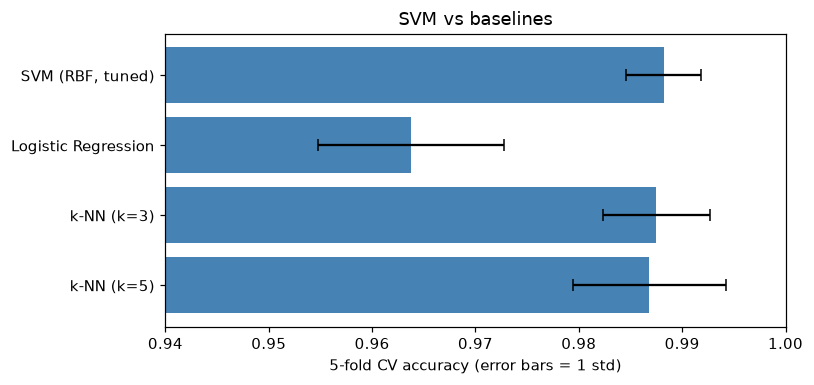

In [155]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier

candidates = {
    "SVM (RBF, tuned)":    best_model,
    "Logistic Regression": Pipeline([("scaler", MinMaxScaler()), ("m", LogisticRegression(max_iter=2000))]),
    "k-NN (k=3)":          Pipeline([("scaler", MinMaxScaler()), ("m", KNeighborsClassifier(3))]),
    "k-NN (k=5)":          Pipeline([("scaler", MinMaxScaler()), ("m", KNeighborsClassifier(5))]),
}
rows = []
for name, model in candidates.items():
    scores = cross_val_score(model, X_train, y_train, cv=cv)
    model.fit(X_train, y_train)
    p_ = model.predict(X_test)
    rows.append({"Model": name, "CV acc": scores.mean(), "CV std": scores.std(),
                 "Test acc": accuracy_score(y_test, p_), "Test macro F1": f1_score(y_test, p_, average="macro")})
baseline = pd.DataFrame(rows).set_index("Model").round(4)
display(baseline)

plt.figure(figsize=(7.5, 3.6))
plt.barh(baseline.index[::-1], baseline["CV acc"][::-1], xerr=baseline["CV std"][::-1],
         capsize=4, color="steelblue")
plt.xlim(0.94, 1.0); plt.xlabel("5-fold CV accuracy (error bars = 1 std)")
plt.title("SVM vs baselines")
plt.tight_layout()
plt.show()

**What this shows (M9)**
- **Final result: 99.2% test accuracy, macro F1 = 0.992**, with only 3 errors in 360 images (two 8s predicted as 1, and one 9 predicted as 7). Digits 0 to 7 all have perfect recall on the test set (every true image was found).
- The weakest digits are 8 (recall 0.94) and 9 (0.97). Digit 1 has the lowest precision (0.95) because it "absorbs" the mistaken 8s.
- With only 3 errors we need more data to see patterns. Over all 1,797 images (cross-validated) the model makes 22 errors (98.8%). The biggest confusion is **8 predicted as 1 (5 times)**, then **5 and 9 (4 times)**, **8 and 9 (3)**, and **3 and 5 (2)**. Our earlier guess about 3/5/8 is partly right (the 3/5 and 8/9 pairs show up), but the counts are tiny, and 4/9 does not appear. Say "slightly more", not "mostly".
- **Baselines:** Logistic Regression is clearly worse (96.4% CV, 95.8% test), about 2.5 to 3.5 points below the SVM. This matches the linear-kernel result and shows the boundary between digits is not linear in pixel space. k-NN is close (k=3 gets 98.75% CV vs the SVM's 98.82%, and 98.6% on test), so the SVM's edge over k-NN is within noise. The SVM's practical advantage is that it needs only its support vectors at prediction time, whereas k-NN must keep and search every training image.
- Caution: with 360 test images, one image is 0.28 percentage points, so ranking the top models by test accuracy alone is unreliable.

---
## Module 10: Seeing the Model (support vectors, errors, PCA)
Numbers are not enough for a presentation. Here we look at what the SVM actually relies on and where it fails.

### 10.1 Support vectors as images
Recall from Module 3: only the **support vectors** (points on or inside the margin) define the model. We now look at which digit images they are.

Support vectors: 664 of 1437 training images (46.2%)
Mean distance to own class average:  support vectors 1.84   vs   other images 1.42


,Train images,Support vectors,% of class,Dist (SV),Dist (non-SV)
0,142,41,28.9,1.52,1.07
1,146,84,57.5,1.96,1.70
2,142,60,42.3,1.99,1.51
3,146,68,46.6,1.78,1.36
4,145,59,40.7,1.94,1.53
5,145,70,48.3,1.91,1.60
6,145,47,32.4,1.68,1.26
7,143,63,44.1,1.84,1.51
8,139,91,65.5,1.79,1.46
9,144,81,56.2,1.86,1.41


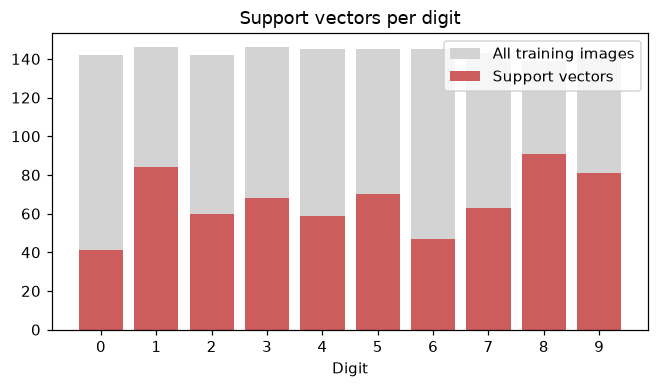

In [156]:
svm = best_model.named_steps["svm"]
is_sv = np.zeros(len(y_train), dtype=bool)
is_sv[svm.support_] = True

# distance of every training image from the average image of its own class (scaled pixels)
class_means = np.array([Xtr_s[y_train == c].mean(axis=0) for c in range(10)])
dist_to_mean = np.linalg.norm(Xtr_s - class_means[y_train], axis=1)

print(f"Support vectors: {is_sv.sum()} of {len(y_train)} training images ({100 * is_sv.mean():.1f}%)")
print(f"Mean distance to own class average:  support vectors {dist_to_mean[is_sv].mean():.2f}"
      f"   vs   other images {dist_to_mean[~is_sv].mean():.2f}")

sv_table = pd.DataFrame({
    "Train images": np.bincount(y_train),
    "Support vectors": svm.n_support_,
    "% of class": (100 * svm.n_support_ / np.bincount(y_train)).round(1),
    "Dist (SV)": [dist_to_mean[is_sv & (y_train == c)].mean().round(2) for c in range(10)],
    "Dist (non-SV)": [dist_to_mean[~is_sv & (y_train == c)].mean().round(2) for c in range(10)],
})
display(sv_table)

plt.figure(figsize=(7, 3.5))
plt.bar(range(10), sv_table["Train images"], color="lightgray", label="All training images")
plt.bar(range(10), sv_table["Support vectors"], color="indianred", label="Support vectors")
plt.xticks(range(10)); plt.xlabel("Digit"); plt.legend(); plt.title("Support vectors per digit")
plt.show()

For digits 3, 8 and 9 we show the **most typical** images that are *not* support vectors (closest to the class average, top row) and the **most atypical** support vectors (farthest from the average, bottom row). These are the two extremes, chosen to make the contrast visible.

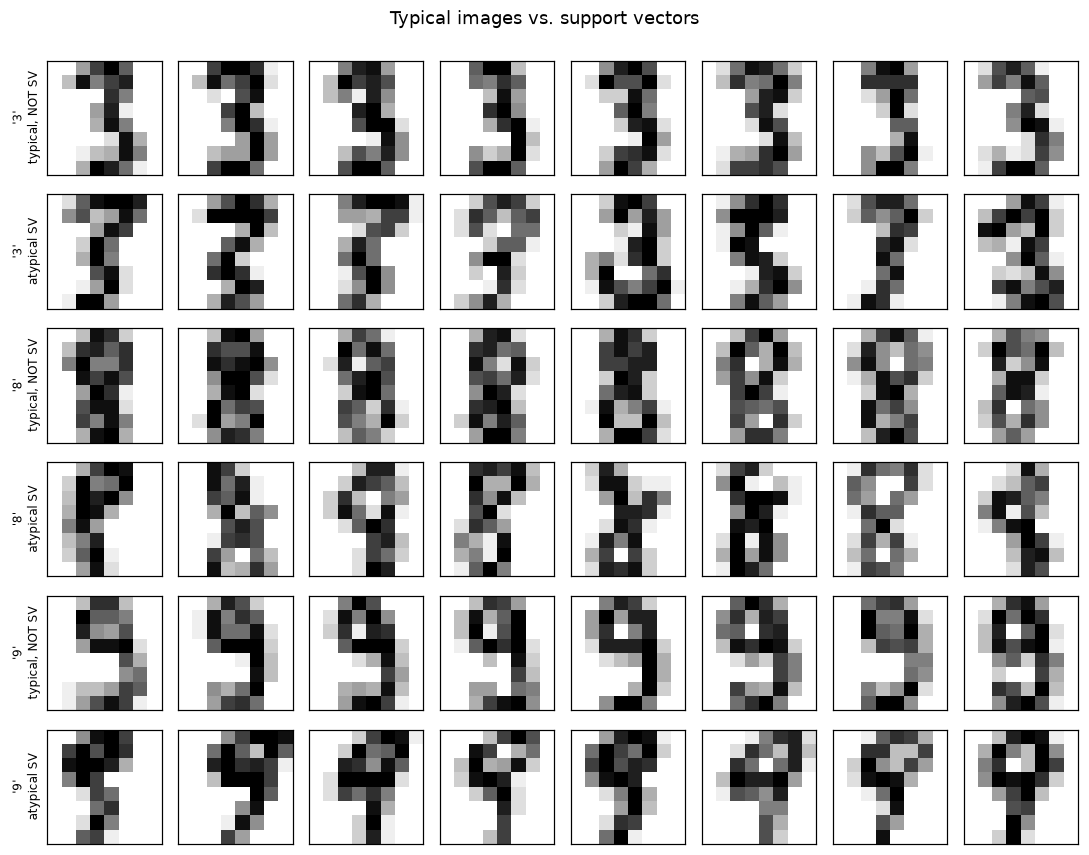

In [157]:
show_digits = [3, 8, 9]
fig, axes = plt.subplots(2 * len(show_digits), 8, figsize=(10, 2.6 * len(show_digits)))
for k, d in enumerate(show_digits):
    non_sv_idx = np.where((y_train == d) & ~is_sv)[0]
    sv_idx = np.where((y_train == d) & is_sv)[0]
    typical = non_sv_idx[np.argsort(dist_to_mean[non_sv_idx])[:8]]
    atypical = sv_idx[np.argsort(-dist_to_mean[sv_idx])[:8]]
    for row, idx, label in [(2 * k, typical, "typical, NOT SV"), (2 * k + 1, atypical, "atypical SV")]:
        for col in range(8):
            ax = axes[row, col]
            ax.imshow(X_train[idx[col]].reshape(8, 8), cmap="gray_r")
            ax.set_xticks([]); ax.set_yticks([])
        axes[row, 0].set_ylabel(f"'{d}'\n{label}", fontsize=8)
plt.suptitle("Typical images vs. support vectors", y=0.995)
plt.tight_layout()
plt.show()

### 10.2 The images the model gets wrong
Using the cross-validated predictions from Module 9 (every image predicted by a model that never saw it), each title shows **true digit → predicted digit**.

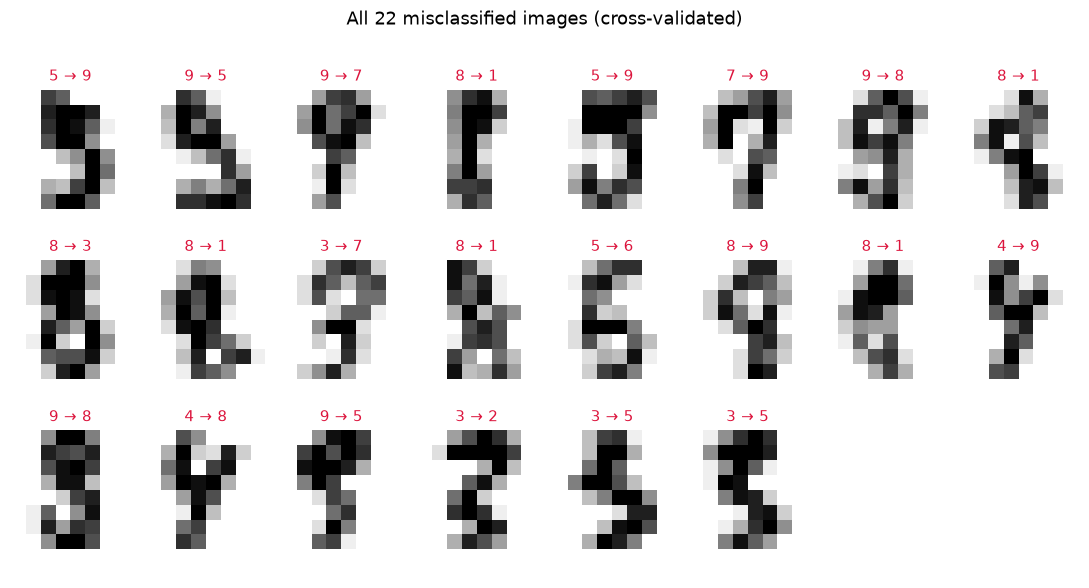

In [158]:
wrong = np.where(pred_cv != y)[0]
ncols = 8
nrows = int(np.ceil(len(wrong) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(10, 1.5 * nrows + 0.8))
for ax in axes.ravel():
    ax.axis("off")
for ax, i in zip(axes.ravel(), wrong):
    ax.imshow(digits.images[i], cmap="gray_r")
    ax.set_title(f"{y[i]} \u2192 {pred_cv[i]}", fontsize=10, color="crimson")
plt.suptitle(f"All {len(wrong)} misclassified images (cross-validated)", y=1.0)
plt.tight_layout()
plt.show()

### 10.3 PCA: squeezing 64 dimensions into a picture
Digits live in 64 dimensions and cannot be drawn. **PCA** finds the directions of largest variance; projecting onto the top 2 or 3 gives a map. (PCA is unsupervised and used here for visualization only.)

Variance explained by PC1, PC2, PC3: [0.148 0.135 0.117]
First 2 components: 28.3%   first 3: 40.0%
Components needed for 90% of variance: 22   for 95%: 30


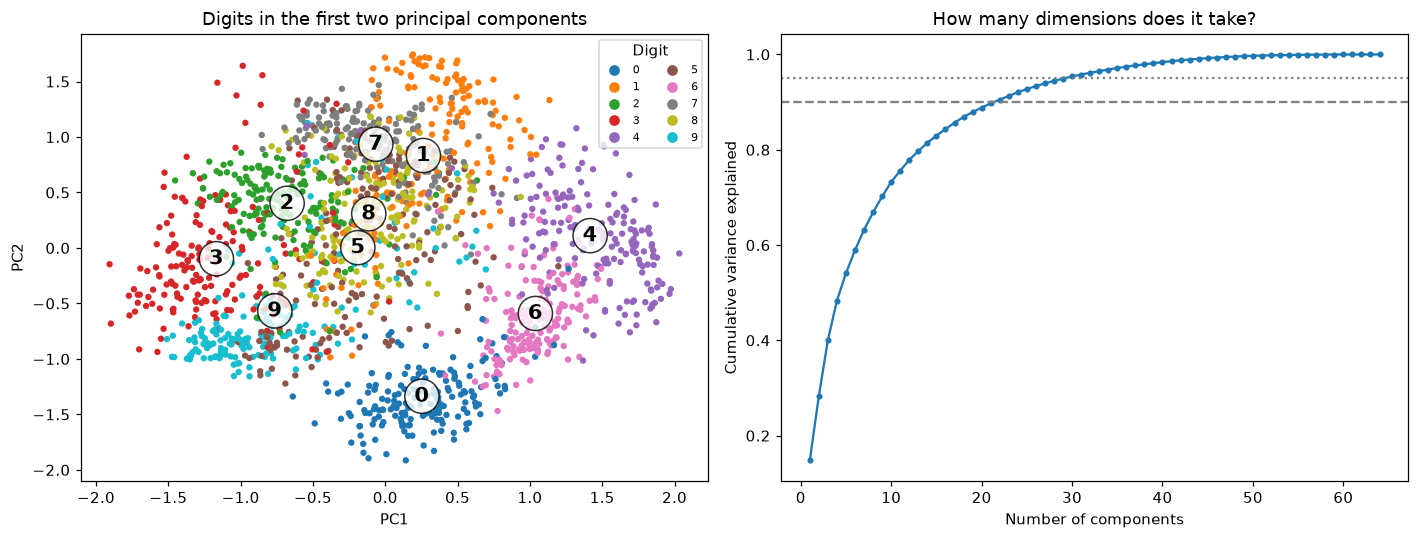

In [159]:
from sklearn.decomposition import PCA

X_all_s = MinMaxScaler().fit_transform(X)
pca_full = PCA().fit(X_all_s)
cum_var = np.cumsum(pca_full.explained_variance_ratio_)
P = PCA(n_components=3).fit_transform(X_all_s)
print("Variance explained by PC1, PC2, PC3:", pca_full.explained_variance_ratio_[:3].round(3))
print("First 2 components:", f"{100 * cum_var[1]:.1f}%", "  first 3:", f"{100 * cum_var[2]:.1f}%")
print("Components needed for 90% of variance:", int(np.argmax(cum_var >= 0.90)) + 1,
      "  for 95%:", int(np.argmax(cum_var >= 0.95)) + 1)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sc = axes[0].scatter(P[:, 0], P[:, 1], c=y, cmap="tab10", s=10)
for d in range(10):
    cx, cy = P[y == d, :2].mean(axis=0)
    axes[0].text(cx, cy, str(d), fontsize=14, weight="bold", ha="center", va="center",
                 bbox=dict(boxstyle="circle", fc="white", ec="k", alpha=0.8))
axes[0].set(xlabel="PC1", ylabel="PC2", title="Digits in the first two principal components")
axes[0].legend(*sc.legend_elements(), title="Digit", loc="upper right", fontsize=7, ncol=2)

axes[1].plot(range(1, 65), cum_var, marker=".")
axes[1].axhline(0.9, color="gray", ls="--"); axes[1].axhline(0.95, color="gray", ls=":")
axes[1].set(xlabel="Number of components", ylabel="Cumulative variance explained",
            title="How many dimensions does it take?")
plt.tight_layout()
plt.show()

### 10.4 How much accuracy survives in 2D? An SVM boundary on PCA space

SVM on just 2 principal components, test accuracy: 0.6333


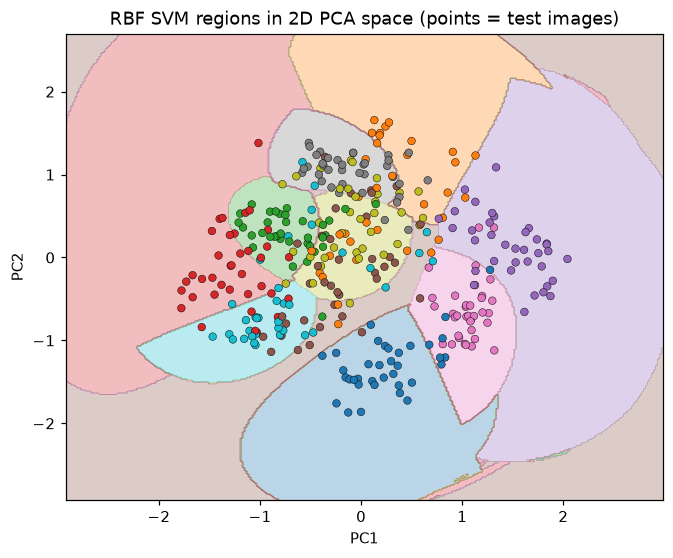

In [160]:
from matplotlib.colors import ListedColormap

pca_pipe = Pipeline([("scaler", MinMaxScaler()), ("pca", PCA(n_components=2)),
                     ("svm", SVC(C=1, gamma="scale"))]).fit(X_train, y_train)
print("SVM on just 2 principal components, test accuracy:", round(pca_pipe.score(X_test, y_test), 4))

Ptr = pca_pipe[:-1].transform(X_train)
Pte = pca_pipe[:-1].transform(X_test)
xx, yy = np.meshgrid(np.linspace(Ptr[:, 0].min() - 1, Ptr[:, 0].max() + 1, 300),
                     np.linspace(Ptr[:, 1].min() - 1, Ptr[:, 1].max() + 1, 300))
zz = pca_pipe.named_steps["svm"].predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

cmap10 = plt.get_cmap("tab10")
plt.figure(figsize=(7, 5.5))
plt.contourf(xx, yy, zz, levels=np.arange(-0.5, 10.5), colors=cmap10(np.arange(10)), alpha=0.3)
plt.scatter(Pte[:, 0], Pte[:, 1], c=y_test, cmap="tab10", edgecolor="k", linewidth=0.3, s=25)
plt.xlabel("PC1"); plt.ylabel("PC2")
plt.title("RBF SVM regions in 2D PCA space (points = test images)")
plt.show()

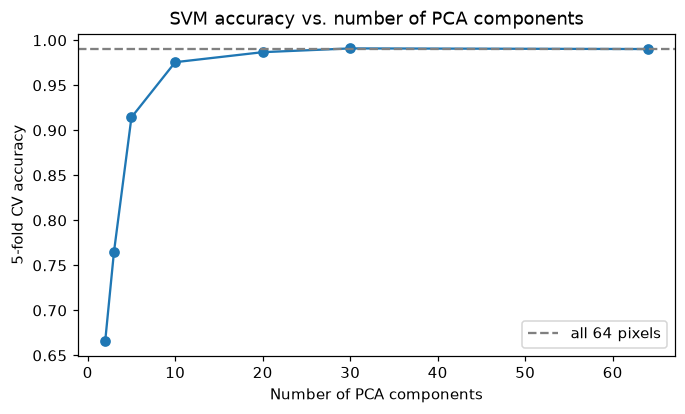

,Components,CV accuracy
0,2,0.6660
1,3,0.7648
2,5,0.9144
3,10,0.9757
4,20,0.9868
5,30,0.9910
6,64,0.9903


In [161]:
ks = [2, 3, 5, 10, 20, 30, 64]
acc_k = []
for k in ks:
    pk = Pipeline([("scaler", MinMaxScaler()), ("pca", PCA(n_components=k)), ("svm", SVC(C=1, gamma="scale"))])
    acc_k.append(cross_val_score(pk, X_train, y_train, cv=cv).mean())

plt.figure(figsize=(7, 3.8))
plt.plot(ks, acc_k, marker="o")
plt.axhline(acc_k[-1], color="gray", ls="--", label="all 64 pixels")
plt.xlabel("Number of PCA components"); plt.ylabel("5-fold CV accuracy")
plt.title("SVM accuracy vs. number of PCA components"); plt.legend()
plt.show()
display(pd.DataFrame({"Components": ks, "CV accuracy": np.round(acc_k, 4)}))

### 10.5 PCA in 3D
Rotate the Plotly version during the presentation. The static plot below always works.

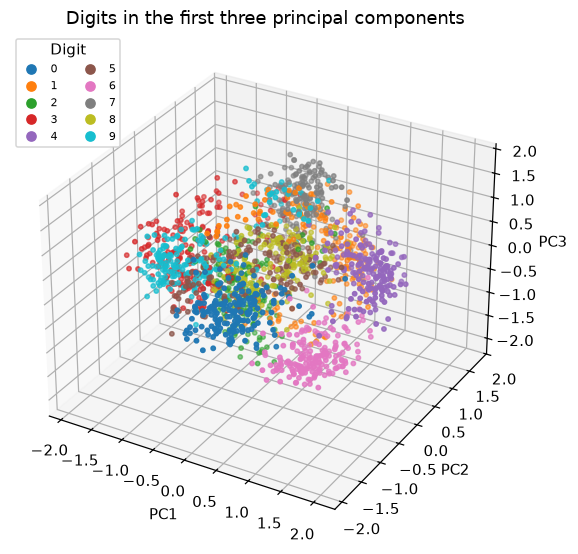

Plotly is not installed. Run: pip install plotly


In [162]:
fig = plt.figure(figsize=(7.5, 6))
ax = fig.add_subplot(111, projection="3d")
sc = ax.scatter(P[:, 0], P[:, 1], P[:, 2], c=y, cmap="tab10", s=8)
ax.set_xlabel("PC1"); ax.set_ylabel("PC2"); ax.set_zlabel("PC3")
ax.set_title("Digits in the first three principal components")
ax.legend(*sc.legend_elements(), title="Digit", loc="upper left", fontsize=7, ncol=2)
plt.show()

try:
    import plotly.express as px
    df3 = pd.DataFrame(P, columns=["PC1", "PC2", "PC3"]); df3["Digit"] = y.astype(str)
    fig3 = px.scatter_3d(df3, x="PC1", y="PC2", z="PC3", color="Digit", opacity=0.75,
                         category_orders={"Digit": [str(d) for d in range(10)]}, height=560,
                         title="Digits in 3D PCA space (interactive)")
    fig3.update_traces(marker=dict(size=2.5))
    fig3.show()
except ImportError:
    print("Plotly is not installed. Run: pip install plotly")

**What this shows (M10)**
- The tuned model keeps **664 of 1,437 training images (46%) as support vectors**. These are far from "just a few points", unlike the 2 support vectors on Iris. In 64 dimensions with 10 classes, many images lie near some class boundary.
- Support vectors are the **atypical** images: on average they are 1.84 away from their own class average, against 1.42 for the other images, and this holds for every digit.
- The digits needing the most support vectors are **8 (66% of its images), 1 (58%) and 9 (56%)**. The fewest are 0 (29%) and 6 (32%). 8 and 9 were also the weakest digits in Module 9, and 1 was the digit that absorbed the mistaken 8s. Digits that sit close to other classes need more support vectors.
- The grid of misclassified images shows all 22 cross-validated errors. Look at them and decide, as a group, how many a human might also hesitate on. Use that as a talking point.
- **PCA:** the first 2 components hold only 28.3% of the variance (3 components: 40.0%). It takes 22 components for 90% and 30 for 95%. So the 2D picture overlaps heavily, and an SVM trained on only 2 components reaches just 63.3% test accuracy. **Do not use the 2D plot as evidence that the classes are hard to separate.** It only shows that two dimensions are not enough.
- Accuracy climbs fast with components: 5 give 91.4%, 10 give 97.6%, 20 give 98.7%, and **30 give 99.1%, the same as all 64 pixels (99.0%)**. Less than half the dimensions are enough.

---
## Module 11: Findings, Limitations, Learnings
### 11.1 All results in one table
The table below is built from the objects computed in earlier modules, so it updates automatically if anything is rerun.

,Test accuracy
Scratch OvR linear SVM (M5),0.9583
"sklearn linear SVM, C=1 (M7)",0.9861
"sklearn RBF SVM, defaults (M7)",0.9917
"RBF SVM, tuned C=1, gamma=0.1 (M8)",0.9917
Logistic Regression (M9),0.9583
"k-NN, k=3 (M9)",0.9861


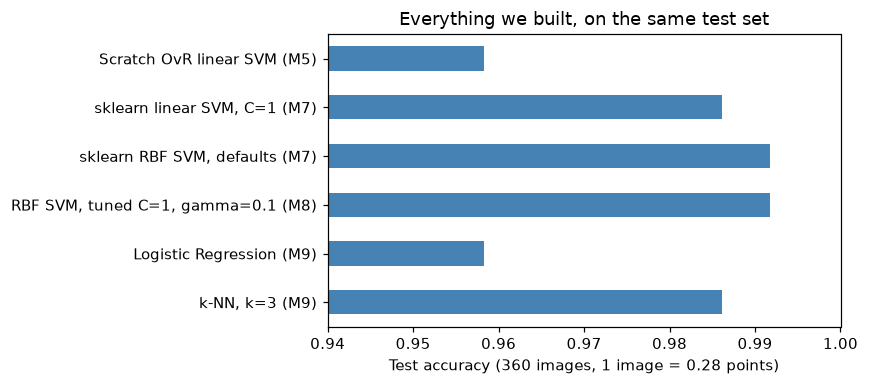

In [163]:
summary = pd.Series({
    "Scratch OvR linear SVM (M5)":      np.mean(pred_ovr == y_test),
    "sklearn linear SVM, C=1 (M7)":     kernel_table.loc["Linear", "Test acc"],
    "sklearn RBF SVM, defaults (M7)":   kernel_table.loc["RBF", "Test acc"],
    "RBF SVM, tuned C=1, gamma=0.1 (M8)": accuracy_score(y_test, pred),
    "Logistic Regression (M9)":         baseline.loc["Logistic Regression", "Test acc"],
    "k-NN, k=3 (M9)":                   baseline.loc["k-NN (k=3)", "Test acc"],
}).round(4)
display(summary.to_frame("Test accuracy"))

plt.figure(figsize=(8, 3.6))
summary[::-1].plot.barh(color="steelblue")
plt.xlim(0.94, 1.0); plt.xlabel("Test accuracy (360 images, 1 image = 0.28 points)")
plt.title("Everything we built, on the same test set")
plt.tight_layout()
plt.show()

### 11.2 A limitation we can measure: sensitivity to noise
A model trained on clean images can behave badly when test images are noisy. We add Gaussian noise (strength $\sigma$, on the 0 to 1 pixel scale) to the **test** images only, average over 5 random draws, and compare:
- our tuned SVM ($\gamma = 0.1$),
- a smoother SVM ($\gamma = 0.01$),
- the tuned SVM trained on the clean images **plus noisy copies** (augmentation),
- Logistic Regression and k-NN.

,SVM tuned (gamma=0.1),SVM smoother (gamma=0.01),SVM tuned + noisy training,Logistic Regression,k-NN (k=3)
sigma=0,0.992,0.958,0.989,0.958,0.986
sigma=0.1,0.789,0.953,0.984,0.952,0.979
sigma=0.2,0.302,0.882,0.967,0.909,0.844
sigma=0.3,0.167,0.627,0.918,0.814,0.627


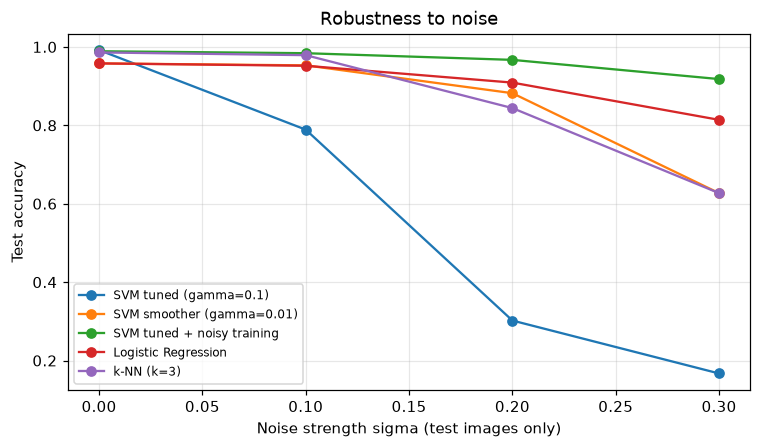

In [164]:
rng = np.random.default_rng(RANDOM_STATE)
def add_noise(Xraw, sigma):
    return np.clip(Xraw / 16 + rng.normal(0, sigma, Xraw.shape), 0, 1) * 16

def make(model):
    return Pipeline([("scaler", MinMaxScaler()), ("m", model)])

X_aug = np.vstack([X_train] + [add_noise(X_train, s) for s in (0.1, 0.2, 0.3)])
y_aug = np.tile(y_train, 4)

noise_models = {
    "SVM tuned (gamma=0.1)":       make(SVC(C=1, gamma=0.1)).fit(X_train, y_train),
    "SVM smoother (gamma=0.01)":   make(SVC(C=1, gamma=0.01)).fit(X_train, y_train),
    "SVM tuned + noisy training":  make(SVC(C=1, gamma=0.1)).fit(X_aug, y_aug),
    "Logistic Regression":         make(LogisticRegression(max_iter=2000)).fit(X_train, y_train),
    "k-NN (k=3)":                  make(KNeighborsClassifier(3)).fit(X_train, y_train),
}
sigmas = [0, 0.1, 0.2, 0.3]
noise_acc = pd.DataFrame(
    {name: [np.mean([m.score(add_noise(X_test, s), y_test) for _ in range(5)]) for s in sigmas]
     for name, m in noise_models.items()}, index=[f"sigma={s}" for s in sigmas]).round(3)
display(noise_acc)

plt.figure(figsize=(8, 4.2))
for name in noise_acc.columns:
    plt.plot(sigmas, noise_acc[name], marker="o", label=name)
plt.xlabel("Noise strength sigma (test images only)"); plt.ylabel("Test accuracy")
plt.title("Robustness to noise"); plt.legend(fontsize=8); plt.grid(alpha=0.3)
plt.show()

**What this shows (11.2)**
- **The tuned SVM is fragile to noise it never saw in training.** At $\sigma = 0.1$ its accuracy falls from 99.2% to 78.9%, and at $\sigma = 0.3$ it reaches 16.7%, close to guessing (10%). Logistic Regression degrades gently (95.8% to 81.4%), and k-NN is robust at low noise (97.9% at $\sigma=0.1$) but falls to 62.7% at $\sigma=0.3$.
- A likely reason (consistent with the results, not proven here): noise increases the squared distance between every pair of images, so with a narrow kernel (large $\gamma$) all similarities shrink towards 0 and the prediction is dominated by the bias term. A smoother kernel ($\gamma = 0.01$) is much more robust (88.2% at $\sigma=0.2$) but costs clean accuracy (95.8% instead of 99.2%). This is the bias-variance trade-off again.
- **The best fix is training on noisy copies** (augmentation): 98.9% clean and still 91.8% at $\sigma=0.3$, the best at every noise level above zero.

---
### 11.3 Key findings
1. **Best model:** RBF SVM with $C=1$, $\gamma=0.1$: **99.2% test accuracy** (3 errors in 360) and 98.8% in cross-validation.
2. **Non-linearity matters:** linear SVM scored 97.8% in CV and Logistic Regression 95.8% on test, below the RBF model. On the toy circles data, linear gets 60% and RBF 100%, and the 3D lift shows why.
3. **$\gamma$ is the sensitive knob**, $C$ much less so. sklearn's default $\gamma$ was already near the best value, so the grid search mostly confirmed it.
4. **Our scratch SVM works:** 95.8% test accuracy from 20 lines of NumPy, matching sklearn's linear OvR SVM (95.3%), and its weights can be drawn as digit templates.
5. **Preprocessing:** pixels are already on one scale, so MinMax scaling was fine and StandardScaler hurt (97.5% vs 99.2%).
6. **Support vectors** are 46% of the data and are the atypical images. Errors concentrate on **8 and 9**, with the most confused pairs 1/8, 5/9, 8/9 and 3/5.
7. **SVM beats Logistic Regression clearly but only edges k-NN** (within noise).

### 11.4 Limitations (with evidence where we have it)
- **Noise sensitivity** (measured above): the model collapses on noisy images unless trained for them.
- **Hyperparameter sensitivity** (Module 8): a poor choice ruins the model, for example $C=0.1$, $\gamma=1$ gives 53.7% CV accuracy.
- **Small test set:** 360 images, so one image is 0.28 points and the top models cannot be ranked reliably by test accuracy alone.
- **Support vectors need storage:** the model keeps 664 images, and kernel SVM training time is known to grow faster than linearly with the number of samples. We did not test large data, so this one is from theory.
- **No probabilities by default** (they need an extra calibration step), and an RBF SVM is hard to interpret.
- **Ignores image structure:** it treats pixels as an unordered list. Convolutional networks use the 2D layout and are the usual choice for large image datasets. We did not test this.

### 11.5 What we learned (edit this to your own words)
- The margin idea is simple, but the real power comes from the **kernel trick**, which gives non-linear boundaries without computing the features.
- **Careful evaluation matters:** cross-validation, a Pipeline without leakage, and honest error bars changed several conclusions (for example, the kernels were not really different, and scaling did not help).
- Looking at **errors, support vectors and failure under noise** taught us more than the accuracy number.

### 11.6 Real-world applications
- **Handwriting and digit recognition:** postal codes, bank cheques, form digitization.
- **Medical diagnosis:** classifying tumours or other conditions from measurements (the breast cancer dataset is the classic example).
- **Text classification:** spam filtering and document topics, where data has very many features and SVMs work well.

**Future work:** noise-augmented training, class weights for imbalanced data, support vector regression, and comparing with a small neural network.